# Kalshi — the venue where resolution is arithmetic

Four notebooks share this directory and they divide the venues between them.
[`polymarket.ipynb`](polymarket.ipynb) covers the offshore venue with the deep
books and the oracle vote, [`predictit.ipynb`](predictit.ipynb) the academic
exemption with 197 political markets and no rules endpoint,
[`iem.ipynb`](iem.ipynb) the 1988 archive, and
[`calibration.ipynb`](calibration.ipynb) puts all of them in one panel and
scores them against each other. Anything **comparative** belongs there; this
notebook stays inside one venue on purpose.

**What is different about this one.** Kalshi is a CFTC-designated contract
market, and the consequence that matters here is not the regulation itself but
what the regulation makes possible: a Kalshi macro contract names the official
statistic it settles against, so resolution is **arithmetic rather than
judgement**. `KXCPIYOY-26SEP-T3.6` pays $1 if the twelve-month change in the
CPI-U for September 2026, as the Bureau of Labor Statistics prints it to one
decimal place, is above 3.6%. There is no oracle, no bond, no "consensus of
credible reporting", and no vote. There is a release, a strike, and a
comparison — and the series on the other side of that comparison is one this
repository already ingests through [`clients/bls.py`](../../clients/bls.py) and
[`clients/fred.py`](../../clients/fred.py). Section 2 works one contract
end to end and closes the join.

The same regulation takes something away, and section 8 measures the absence
rather than asserting it: no US-registered venue may list a contract on war,
terrorism or assassination, so the single thing Polymarket has that nothing
else does is permanently missing here.

**What this notebook is not.** It is not advice and it does not recommend a
trade. Every number below is either read off disk from the harvested corpus or
fetched read-only and unauthenticated, and where a measure cannot be computed
from public data it is named as uncomputable rather than approximated. Nothing
here holds a key, signs anything, or places an order; the venue is being
measured, not traded.

**The facts it rests on** are in
[`sefer/planning/polymarket-event-probabilities.md`](../../../sefer/planning/polymarket-event-probabilities.md),
a five-pass research run of 2026-09-26 with an adversarial verification pass.
Where this notebook re-measures one of those figures it says so; where it
quotes one it does not re-derive it.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file, and
# then a relative "utils/" resolves somewhere else entirely and the imports below
# fail with ModuleNotFoundError.
_here = Path.cwd()
_PM = _here if (_here / "utils" / "kalshi.py").exists() else _here / "notebooks" / "prediction_markets"
for _path in (str(_PM), str(_PM.parents[1])):        # notebooks/prediction_markets, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

import asyncio
import json
import math
import re
import statistics
import time
from collections import Counter, defaultdict
from datetime import UTC, date, datetime, timedelta
from typing import Any, Iterable, Sequence

import numpy
from matplotlib import colors as mcolors
from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call honest,
# since the stubs type these parameters as floats.
from matplotlib.dates import DateFormatter, YearLocator, date2num
from matplotlib.figure import Figure
from numpy.typing import NDArray

from lib import config
from utils import corpus, kalshi, metrics

pyplot.style.use(config.glyfish_style)

DATA = _PM / "data"

#: The venue is polled at most this many times by one run of this notebook, and
#: the ledger below refuses the call that would exceed it. The harvest that built
#: `data/` already spent tens of thousands of requests; a teaching notebook has
#: no business adding to that, and every number that can come off disk does.
LIVE_BUDGET = 20

#: Palette, fixed here so that the same meaning keeps the same colour across
#: eight figures. Kalshi blue for the venue, orange for the world's answer,
#: purple for the long-dated contrast, grey for anything unexecutable.
BLUE, ORANGE, PURPLE = "#0067C4", "#FF9500", "#320075"
PALE, YELLOW = "#329EFF", "#FFE800"

#: A sequential ramp for an ORDERED set of rungs, built from the house palette
#: rather than from a stock colormap: eleven deadlines on one question have to
#: read as a sequence, and the general-purpose maps pass through a desaturated
#: middle that reads as "excluded" instead of "in between".
RUNG_RAMP = mcolors.LinearSegmentedColormap.from_list(
    "rungs", ["#9ECBFF", "#329EFF", "#0067C4", "#5600C9", "#320075"])


class Ledger:
    """A read-only Kalshi reader with a hard call ceiling and a printed account.

    `kalshi.Reader` already paces itself and honours `Retry-After`; what this
    adds is a budget that cannot be overspent by accident and a record of what
    each call was for, so the cost of the notebook is auditable from its own
    output rather than from the venue's logs.
    """

    def __init__(self, budget: int = LIVE_BUDGET, pace: float = 0.35) -> None:
        self.budget = budget
        self.reader = kalshi.Reader(pace=pace)
        self.calls: list[tuple[str, str]] = []

    def spend(self, purpose: str, label: str = "") -> None:
        if len(self.calls) >= self.budget:
            raise RuntimeError(
                f"live-call budget of {self.budget} exhausted; "
                f"the last call was {self.calls[-1][0]!r}")
        self.calls.append((purpose, label))

    def account(self) -> None:
        print(f"{len(self.calls)} outbound calls of {self.budget} budgeted, of which "
              f"{self.reader.n_requests} went to Kalshi "
              f"({self.reader.n_429} retried on 429)")
        for i, (purpose, label) in enumerate(self.calls, start=1):
            print(f"  {i:2}. {purpose:34} {label}")


LIVE = Ledger()


def stamp(*names: str, figure: Figure | None = None) -> None:
    """Name the route or the file a figure was drawn from, along its bottom edge.

    The FBI notebooks stamp figures with the requests behind them
    (`notebooks/fbi/utils/filing.py`); the same discipline applies here, and it
    matters more, because half of these figures come off disk and half come off
    the wire and a reader cannot otherwise tell which.
    """
    figure = figure or pyplot.gcf()
    figure.subplots_adjust(bottom=max(0.17, 0.11 + 0.032 * len(names)))
    figure.text(0.995, 0.005, "\n".join(names), ha="right", va="bottom",
                fontsize=7, family="monospace", alpha=0.65)


def read_rows(name: str) -> list[dict[str, Any]]:
    """One harvested JSONL file as a list of dicts."""
    return kalshi.read_jsonl(name, data_dir=DATA)


def quantile(values: Sequence[float], q: float) -> float:
    """A plain order statistic, so a one-number summary needs no dependency."""
    ordered = sorted(values)
    if not ordered:
        return float("nan")
    return ordered[min(len(ordered) - 1, int(q * len(ordered)))]


print(f"python {sys.version.split()[0]}   numpy {numpy.__version__}")
print(f"corpus under {DATA}")
print(f"live-call budget {LIVE_BUDGET}, paced at {LIVE.reader.pace:.2f}s between requests")

python 3.14.7   numpy 2.4.6
corpus under /Users/troy/Develop/gly.fish/meida/notebooks/prediction_markets/data
live-call budget 20, paced at 0.35s between requests


## 1. Series, event, market — and the two tiers underneath

Kalshi's unit of description is not the market. It is a three-level tree, and
every useful property lives at a different level:

* a **series** is the recurring question — `KXCPIYOY`, "Inflation" — and it
  carries the things that do not change month to month: the settlement
  sources, the filed contract-terms PDF, the fee family, and who is barred
  from trading it;
* an **event** is one instance — `KXCPIYOY-26SEP`, September 2026 — and it
  carries `mutually_exclusive`, which says whether its markets partition an
  outcome space or stack up as a cumulative ladder;
* a **market** is one rung — `KXCPIYOY-26SEP-T3.6`, "Above 3.6%" — and it
  carries the strike, the quote, the rules prose and, once it is over, the
  settlement record.

This is more structure than Polymarket gives, and the difference is not
cosmetic. Polymarket's `series_id` covers roughly a third of its open
geopolitics events, so grouping a row of related markets into one question
needs a hand-maintained concept map; Kalshi states the grouping, states
whether it is exclusive, and puts the strike in a typed numeric field. Section
4 spends that structure.

The census below is read off the harvested catalogue rather than re-walked.

In [2]:
series_rows: list[dict[str, Any]] = read_rows("kalshi_series.jsonl")
census: dict[str, Any] = json.loads((DATA / "kalshi_census.json").read_text())

by_category = Counter(s["category"] for s in series_rows)
print(f"{len(series_rows):,} series in the catalogue, one ~17 MB unpaginated response")
print(f"{'category':26} {'series':>7}")
for name, n in by_category.most_common(8):
    print(f"{name:26} {n:7,}")
print(f"{'… ' + str(len(by_category) - 8) + ' further categories':26} "
      f"{sum(n for _, n in by_category.most_common()[8:]):7,}")

print(f"\nthe four categories this project cares about: "
      f"{census['target_series']:,} series, {census['statistical_series']:,} of them "
      f"settling on a named official statistic")

# The market corpus is deliberately reported twice, because the two numbers
# differ and the difference is a documented property of the API rather than a
# harvest bug: a market settled just before the historical cutoff is served by
# BOTH the live and the historical walk, so concatenating them double-counts a
# band. De-duplication is on ticker.
tickers: Counter[str] = Counter()
tiers: dict[str, set[str]] = defaultdict(set)
for line in (DATA / "kalshi_markets.jsonl").open():
    row = json.loads(line)
    tickers[row["ticker"]] += 1
    tiers[row["ticker"]].add(row["tier"])
both = sum(1 for t, seen in tiers.items() if len(seen) > 1)
print(f"\n{sum(tickers.values()):,} market rows walked -> {len(tickers):,} unique tickers "
      f"({sum(tickers.values()) - len(tickers):,} duplicated, {both:,} of them served by both tiers)")
print(f"settled: {census['settled']:,}   by year: "
      + "  ".join(f"{y} {n:,}" for y, n in sorted(census['settled_years'].items())))
print(f"by tier: " + "  ".join(f"{k} {v:,}" for k, v in census["by_tier"].items()))

14,392 series in the catalogue, one ~17 MB unpaginated response
category                    series
Sports                       3,782
Entertainment                2,546
Politics                     2,374
Elections                    1,810
Financials                     974
Economics                      815
Mentions                       448
Climate and Weather            409
… 12 further categories      1,234

the four categories this project cares about: 5,973 series, 653 of them settling on a named official statistic



105,205 market rows walked -> 100,395 unique tickers (4,810 duplicated, 1,962 of them served by both tiers)
settled: 100,233   by year: 2021 143  2022 2,330  2023 5,994  2024 5,995  2025 10,510  2026 75,261
by tier: historical 55,763  live 44,632


**The tier split is the one thing to know before reading anything else.**
Kalshi partitions market data by a moving cutoff. A market that settled before
it **404s on every live route** — the market lookup, the nested-markets event
read, and the candlestick path — and is served instead by a parallel
`/historical/...` family. Probe only the live tier and the honest conclusion
from the evidence is that Kalshi deletes its past. It does not; it moves it.

`utils/kalshi.py` routes across the split, so the rest of this notebook does
not think about it. The cell below makes the split visible, because a reader
who has not seen the 404 will not believe it is there. Four live calls, on one
CPI rung that settled on 10 June 2026 — before the cutoff, and therefore
invisible to every live route.

In [3]:
LIVE.spend("GET /historical/cutoff", "the moving tier boundary")
cutoff = LIVE.reader.cutoff()
print("cutoff, as the venue reports it:")
for key, raw in cutoff["_raw"].items():
    print(f"  {key:34} {raw}")
boundary = datetime.fromtimestamp(cutoff["market_settled_ts"], UTC)
print(f"\nmarkets settled before {boundary:%Y-%m-%d} are historical-tier only "
      f"— a trailing window of {(datetime.now(UTC) - boundary).days} days as of today")

SETTLED_RUNG = "KXCPIYOY-26MAY-T3.5"        # settled 2026-06-10, i.e. pre-cutoff
probes: list[tuple[str, str]] = [
    (f"/markets/{SETTLED_RUNG}", "live market lookup"),
    (f"/historical/markets/{SETTLED_RUNG}", "historical market lookup"),
    (f"/series/KXCPIYOY/markets/{SETTLED_RUNG}/candlesticks", "live candlestick path"),
    (f"/historical/markets/{SETTLED_RUNG}/candlesticks", "historical candlestick path"),
]
span = {"start_ts": int(datetime(2026, 6, 1, tzinfo=UTC).timestamp()),
        "end_ts": int(datetime(2026, 6, 11, tzinfo=UTC).timestamp()),
        "period_interval": 1440}
print(f"\n{SETTLED_RUNG}, on the four routes that could serve it:")
for path, what in probes:
    LIVE.spend(f"GET {path.split('/')[1]}…", what)
    payload = LIVE.reader.get(path, allow_404=True,
                             **(span if path.endswith("candlesticks") else {}))
    if payload is None:
        print(f"  {what:28} 404 — the route denies the market exists")
    else:
        served = (payload.get("candlesticks") if "candlesticks" in payload
                  else [payload.get("market")])
        print(f"  {what:28} 200 — {len(served or []):>3} "
              f"{'candles' if 'candlesticks' in payload else 'market record'}")

cutoff, as the venue reports it:
  market_positions_last_updated_ts   2026-07-28T00:00:00Z
  market_settled_ts                  2026-07-28T00:00:00Z
  orders_updated_ts                  2026-09-12T00:00:00Z
  trades_created_ts                  2026-07-28T00:00:00Z

markets settled before 2026-07-28 are historical-tier only — a trailing window of 60 days as of today

KXCPIYOY-26MAY-T3.5, on the four routes that could serve it:


  live market lookup           404 — the route denies the market exists


  historical market lookup     200 —   1 market record


  live candlestick path        404 — the route denies the market exists


  historical candlestick path  200 —   8 candles


The two tiers also **rename every numeric field**: live says
`price.close_dollars`, `volume_fp`, `open_interest_fp`; historical says
`price.close`, `volume`, `open_interest`, for the identical object. Code
written against one tier reads zeros and empty prices from the other without
erroring. `kalshi.normalise_candle` and `kalshi.normalise_market` collapse both
onto one shape, which is why nothing below has to care.

**How a settled market reports its result** is the part Polymarket has no
analogue for. Four fields carry it, and they answer different questions:

| field | what it says |
| --- | --- |
| `result` | `yes`, `no`, `""` while open — or `scalar`, which is a trap |
| `settlement_value` | the payout per contract, in dollars |
| `expiration_value` | **what the world actually did**, as a human string |
| `settlement_ts` | when the exchange stamped it |

`expiration_value` is the one that matters and the one no other venue serves.
Polymarket tells you which side won; Kalshi tells you the number that decided
it. That single string is what makes the join in section 2 checkable at all.

`result == "scalar"` is excluded from everything scored below. A scalar market
did not settle against the world: Kalshi halted it and paid out at a price,
so its "outcome" is its own last quote, and scoring that as truth makes any
forecast look perfect. `kalshi.outcome` returns `None` for those 162 markets
and `corpus.load_kalshi` drops them, keeping `settlement_value` on the row so
the exclusion stays auditable.

In [4]:
markets_by_event: dict[str, list[dict[str, Any]]] = defaultdict(list)
for line in (DATA / "kalshi_markets.jsonl").open():
    row = json.loads(line)
    if row["series_ticker"] in ("CPIYOY", "KXCPIYOY"):
        markets_by_event[row["event_ticker"]].append(row)

example = next(m for m in markets_by_event["KXCPIYOY-26MAY"] if m["ticker"] == SETTLED_RUNG)
print(f"{example['ticker']} — {example['title']}")
for field in ("strike_type", "floor_strike", "yes_sub_title", "open_time", "close_time",
              "expected_expiration_time", "expiration_time", "settlement_ts",
              "status", "result", "settlement_value", "expiration_value",
              "volume", "open_interest", "liquidity"):
    print(f"  {field:26} {example[field]!r}")
print(f"\n  rules_primary: {example['rules_primary']}")
print(f"  rules_secondary: {example['rules_secondary'][:150]}…")

# Two things in that record are worth stopping on, and both recur below.
#
# (1) close_time is 91 minutes BEFORE expected_expiration_time, and one minute
#     before the BLS release: the contract stops trading at 08:29 ET and the
#     number lands at 08:30. Nobody trades the print.
# (2) open_interest and liquidity both read 0.0 on a settled row. They are live
#     position and book measures, not historical records, and section 6 recovers
#     the interest this market actually carried from its candles instead.
closes = datetime.fromisoformat(example["close_time"].replace("Z", "+00:00"))
expires = datetime.fromisoformat(example["expected_expiration_time"].replace("Z", "+00:00"))
print(f"\n  trading stops {(expires - closes).total_seconds() / 60:.0f} minutes before "
      f"the expected expiration, i.e. {closes:%H:%M} UTC against a 12:30 UTC release")

KXCPIYOY-26MAY-T3.5 — Will the rate of CPI inflation be above 3.5% for the year ending in May 2026?
  strike_type                'greater'
  floor_strike               3.5
  yes_sub_title              'Above 3.5%'
  open_time                  '2026-03-18T16:00:00Z'
  close_time                 '2026-06-10T12:29:00Z'
  expected_expiration_time   '2026-06-10T14:00:00Z'
  expiration_time            '2026-09-09T14:00:00Z'
  settlement_ts              '2026-06-10T13:36:24.520345Z'
  status                     'finalized'
  result                     'yes'
  settlement_value           1.0
  expiration_value           '4.2'
  volume                     14760.23
  open_interest              0.0
  liquidity                  0.0

  rules_primary: If the Consumer Price Index (CPI) increases by more than 3.5% in the twelve months ending May 2026 (as represented by the one-decimal place value reported by the Bureau of Labor Statistics), then the market resolves to Yes.
  rules_secondary: In the cas

### The settled result, recovered from the ladder alone

One event in the CPI corpus does not report its realised value as a number:
`KXCPIYOY-26AUG` reports the string `"Above 3.3%"`. That is not a defect to
work around, it is the demonstration — because the ladder's own yes/no
boundary pins the print to a single tenth without reading the field at all.
Every rung at or below 3.3 settled `yes` and every rung at or above 3.4
settled `no`, so the twelve-month change was in (3.3, 3.4], and since BLS
publishes it to one decimal place that is exactly 3.4.

Resolution being arithmetic means the arithmetic can be run backwards. The
next cell does that for all 46 events, and section 2 checks the answer against
the agency.

In [5]:
_STRIKE_IN_LABEL = re.compile(r"(-?\d+(?:\.\d+)?)")


def rung_strike(rung: dict[str, Any]) -> float | None:
    """The rung's strike, from the typed field or — on older events — from its label.

    `floor_strike` is a **newer convention than the venue itself**. On
    `CPIYOY-22NOV`, `-23SEP` and `-23NOV` every rung carries `strike_type: None`
    and `floor_strike: None`, and the strike exists only in `yes_sub_title`
    ("Above 7.9%") and in the ticker suffix. So anything keyed on the typed field
    silently drops Kalshi's first two years, which is exactly the kind of
    vocabulary drift a catalogue has to absorb rather than inherit. Parse the
    label as the fallback and say so.
    """
    if rung.get("floor_strike") is not None:
        return float(rung["floor_strike"])
    match = _STRIKE_IN_LABEL.search(rung.get("yes_sub_title") or "")
    return float(match.group(1)) if match else None


def boundary_value(rungs: Sequence[dict[str, Any]]) -> tuple[float | None, float | None]:
    """The realised value bracketed by a settled `greater`-strike ladder.

    Returns `(highest yes strike, lowest no strike)`. For a coherent ladder the
    realised number lies in that half-open interval, and where the strikes are
    one tenth apart the interval names a single printed value. A ladder that
    settled incoherently — a `no` below a `yes` — returns a reversed pair, which
    is why both ends are handed back rather than a midpoint. A ladder whose rungs
    all settled the same way brackets nothing: the print was outside every listed
    strike and the field is the only witness.
    """
    yes = [s for r in rungs if r["result"] == "yes"
           and (s := rung_strike(r)) is not None]
    no = [s for r in rungs if r["result"] == "no"
          and (s := rung_strike(r)) is not None]
    return (max(yes) if yes else None, min(no) if no else None)


def stated_value(rungs: Sequence[dict[str, Any]]) -> str | None:
    """The event's `expiration_value`, as the rows spell it — verbatim, warts on."""
    spellings = {r["expiration_value"] for r in rungs if r.get("expiration_value")}
    return sorted(spellings)[0] if spellings else None


print(f"{'event':18} {'stated':12} {'yes ≤':>6} {'no ≥':>6} {'bracketed':>10} {'rungs':>6}")
cpi_events: dict[str, dict[str, Any]] = {}
for event in sorted(markets_by_event):
    rungs = markets_by_event[event]
    lo, hi = boundary_value(rungs)
    stated = stated_value(rungs)
    bracket = f"{hi:.1f}" if lo is not None and hi is not None and abs(hi - lo - 0.1) < 1e-9 else "—"
    cpi_events[event] = {"rungs": rungs, "stated": stated, "yes_max": lo, "no_min": hi,
                         "bracketed": float(bracket) if bracket != "—" else None}
    if event in ("CPIYOY-22NOV", "CPIYOY-23APR", "KXCPIYOY-25APR", "KXCPIYOY-25OCT",
                 "KXCPIYOY-26MAY", "KXCPIYOY-26JUN", "KXCPIYOY-26AUG"):
        print(f"{event:18} {str(stated):12} {lo if lo is not None else float('nan'):6.1f} "
              f"{hi if hi is not None else float('nan'):6.1f} {bracket:>10} {len(rungs):6}")

agree = sum(1 for v in cpi_events.values() if v["bracketed"] is not None)
typed = sum(1 for v in cpi_events.values()
            if any(r.get("floor_strike") is not None for r in v["rungs"]))
print(f"\n{len(cpi_events)} monthly CPI-YoY events; the rung boundary names a single "
      f"tenth on {agree} of them")
print(f"{typed} of them carry a typed `floor_strike` at all — the rest are pre-2024 "
      f"and hold their strike only in the label, which `rung_strike` parses")
one_sided = [e for e, v in cpi_events.items()
             if v["yes_max"] is None or v["no_min"] is None]
print(f"and {len(one_sided)} bracket nothing because every rung settled the same way, "
      f"i.e. the print landed outside the listed strikes: {', '.join(one_sided)}")
print("spellings of expiration_value across those events: "
      + ", ".join(sorted({repr(v['stated']) for v in cpi_events.values()})[:8]) + " …")
print("— a human string, not a number: bare, two-decimal, percent-suffixed and "
      "relative forms all appear, so it must be parsed rather than cast")

event              stated        yes ≤   no ≥  bracketed  rungs
CPIYOY-22NOV       7.1             7.0    7.1        7.1     13
CPIYOY-23APR       4.9             4.8    4.9        4.9     22
KXCPIYOY-25APR     2.30            2.2    2.3        2.3     10
KXCPIYOY-25OCT     3.3             3.1    nan          —      8
KXCPIYOY-26AUG     Above 3.3%      3.3    3.4        3.4     26
KXCPIYOY-26JUN     3.5%            3.4    3.5        3.5     21
KXCPIYOY-26MAY     4.2             4.1    4.2        4.2     27

46 monthly CPI-YoY events; the rung boundary names a single tenth on 45 of them
43 of them carry a typed `floor_strike` at all — the rest are pre-2024 and hold their strike only in the label, which `rung_strike` parses
and 1 bracket nothing because every rung settled the same way, i.e. the print landed outside the listed strikes: KXCPIYOY-25OCT
spellings of expiration_value across those events: '2.30', '2.4%', '2.4', '2.40', '2.50', '2.60', '2.7%', '2.7' …
— a human string, not a nu

## 2. The settlement source, and the join

This is the section the notebook exists for.

Polymarket resolves on "a consensus of credible sources", adjudicated by a
bonded proposal and, when challenged, a token-holder vote — and the research
doc records three eight-figure markets where that machinery produced an answer
a reasonable reader would dispute. Kalshi resolves on a **named source
agency**. The field is `settlement_sources` on the series, it is filled on
5,969 of the 5,973 series in the four categories this project cares about, and
on 653 of them it names a statistical agency rather than a newspaper.

What that buys is not just confidence in the resolution. It is a **key**. A
contract that settles on the BLS CPI-U print can be joined to the CPI-U series
— the actual series, the one in `clients/bls.py` — on the settlement source
itself, with no name-matching, no fuzzy join and no concept map. And because
the settled market carries `expiration_value`, the join is *checkable*: fetch
the statistic, compute the number the contract names, and compare it to what
the exchange said the world did.

The census first, off disk.

In [6]:
TARGET = ("Economics", "Financials", "Politics", "Elections")
target_series = [s for s in series_rows if s["category"] in TARGET]
statistical = [s for s in target_series if s["is_statistical"]]

print(f"{len(target_series):,} series in {', '.join(TARGET)}")
print(f"  {sum(1 for s in target_series if s['source_names']):,} name a settlement "
      f"source at all")
print(f"  {len(statistical):,} settle against a named statistical agency")
print(f"  {sum(1 for s in target_series if s['contract_terms_url']):,} carry a filed "
      f"contract-terms PDF")
print(f"  {sum(1 for s in target_series if s['contract_url']):,} carry a CFTC product "
      f"certification")
print(f"  {sum(1 for s in target_series if any('Source Agenc' in p for p in s['additional_prohibitions'] or [])):,} "
      f"bar the source agency's own employees from trading them")

# `house_upstream` is a set per series and a series may name several agencies, so
# reading the upstream off co-occurring series conflates them. The mapping itself
# is the answer: kalshi.SETTLEMENT_UPSTREAM is the registry, and printing it is
# printing the join.
print(f"\n{'agency':12} {'series':>7}  joins to")
agencies = Counter(a for s in target_series for a in s["agencies"])
for agency, n in agencies.most_common():
    house, _ = kalshi.SETTLEMENT_UPSTREAM[agency]
    print(f"{agency:12} {n:7}  {house}")
print(f"{'':12} {'':7}  — a keyword match over the settlement name and URL, so it "
      f"is a candidate list and not a curated one; section 10 says what that costs")

# The cleanest 40-odd of them name a literal FRED series id in the settlement
# URL, which is the join with no inference at all: the contract says which row
# of which table it reads.
fred_linked = [s for s in series_rows if s["fred_series_ids"]]
print(f"\n{len(fred_linked)} series name a FRED series id outright in their settlement URL:")
print(f"  {'series':22} {'FRED id(s)':28} title")
for s in sorted(fred_linked, key=lambda s: s["ticker"])[:12]:
    print(f"  {s['ticker']:22} {','.join(s['fred_series_ids']):28} {s['title'][:44]}")
print(f"  … and {len(fred_linked) - 12} more")

5,973 series in Economics, Financials, Politics, Elections
  5,969 name a settlement source at all
  653 settle against a named statistical agency
  5,973 carry a filed contract-terms PDF
  5,961 carry a CFTC product certification
  5,106 bar the source agency's own employees from trading them

agency        series  joins to
fed              261  FRED
bls              258  BLS
treasury          68  FRED
eia               60  EIA
fred              55  FRED
census            12  FRED
bea               12  FRED
                      — a keyword match over the settlement name and URL, so it is a candidate list and not a curated one; section 10 says what that costs

43 series name a FRED series id outright in their settlement URL:
  series                 FRED id(s)                   title
  10Y2Y                  T10Y2Y                       Treasury spread 10Y-2Y
  10Y3M                  T10Y3M                       Treasury spread 10Y-3M
  ECONPATH               CPIAUCSL,UNRATE          

### One contract, end to end

`KXCPIYOY` — "Inflation" — is the right one to work, for four reasons: it is
monthly, so there are 46 settled events rather than one; it is a strike ladder,
so section 4 can reuse it; it settles on a statistic this repository already
fetches; and its rules name the *rounding*, which turns out to matter.

One live call for the series record.

In [7]:
LIVE.spend("GET /series/KXCPIYOY", "settlement sources, terms, fee family")
cpi_series = LIVE.reader.series("KXCPIYOY")
assert cpi_series is not None
classified = kalshi.classify_settlement(cpi_series.get("settlement_sources"))

print(f"series          {cpi_series['ticker']} — {cpi_series['title']}")
print(f"category        {cpi_series['category']}   frequency {cpi_series['frequency']}")
print(f"fee family      {cpi_series['fee_type']}   multiplier {cpi_series['fee_multiplier']}")
print(f"terms           {cpi_series['contract_terms_url']}")
print(f"certification   {cpi_series.get('contract_url')}")
print("settlement sources:")
for source in cpi_series.get("settlement_sources") or []:
    print(f"  {source.get('name')}  <{source.get('url')}>")
print(f"classified      agencies={classified['agencies']} "
      f"house_upstream={classified['house_upstream']} "
      f"is_statistical={classified['is_statistical']}")
print("prohibitions:")
for rule in cpi_series.get("additional_prohibitions") or []:
    print(f"  • {rule}")

rules = next(m["rules_primary"] for m in cpi_events["KXCPIYOY-26MAY"]["rungs"]
             if m["ticker"] == SETTLED_RUNG)
print(f"\nand the rung's own rule, verbatim:\n  {rules}")

series          KXCPIYOY — Inflation
category        Economics   frequency monthly
fee family      quadratic_with_maker_fees   multiplier 1
terms           https://assets.kalshi.com/contract_terms/YOYCPI.pdf
certification   https://assets.kalshi.com/regulatory/product-certifications/YOYCPI.pdf
settlement sources:
  Bureau of Labor Statistics  <https://www.bls.gov/cpi/>
classified      agencies=['bls'] house_upstream=['BLS'] is_statistical=True
prohibitions:
  • Persons who are employed by any of the Source Agencies are not permitted to trade on the Contract.
  • Persons who hold any material, non-public information on the Underlying are not permitted to trade on the Contract.

and the rung's own rule, verbatim:
  If the Consumer Price Index (CPI) increases by more than 3.5% in the twelve months ending May 2026 (as represented by the one-decimal place value reported by the Bureau of Labor Statistics), then the market resolves to Yes.


Three things in that rule decide how the join has to be built, and only one of
them is obvious.

1. **"the Consumer Price Index (CPI)"** — the headline all-items CPI-U, which
   is `CUUR0000SA0` at BLS and `CPIAUCNS` at FRED.
2. **"increases by more than 3.5% in the twelve months ending May 2026"** — a
   twelve-month percent change, not an annualised rate and not a monthly one.
3. **"as represented by the one-decimal place value reported by the Bureau of
   Labor Statistics"** — and this is the load-bearing clause. The contract does
   not settle on the index; it settles on **BLS's own rounding of the
   derivative**. So the right join is not "fetch the index and compute a
   change", it is "fetch the number BLS publishes", and BLS publishes exactly
   that: `calculations.pct_changes["12"]` on the observation, to one decimal.

What the rule does **not** say is whether the index is seasonally adjusted.
The contract names an agency and a concept, and leaves the series ambiguous —
which is the kind of gap that has to be closed by measurement rather than by
reading. The next cell closes it: the same 46 settlements, checked against the
not-seasonally-adjusted index and against the seasonally adjusted one. Two
calls out of the house, one to each upstream.

In [8]:
from clients.bls import BlsClient                                   # noqa: E402
from clients.fred import FredClient                                 # noqa: E402

MONTHS = {m: i for i, m in enumerate(
    ("JAN", "FEB", "MAR", "APR", "MAY", "JUN",
     "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"), start=1)}


def event_month(event_ticker: str) -> str | None:
    """The reference month a CPI event names, as `YYYY-MM`.

    The ticker carries it — `KXCPIYOY-26MAY` is May 2026 — which is the only
    machine-readable statement of *which print* the contract reads. The title
    says it too, in prose.
    """
    match = re.search(r"-(\d\d)([A-Z]{3})$", event_ticker)
    if not match:
        return None
    return f"20{match.group(1)}-{MONTHS[match.group(2)]:02d}"


def stated_number(value: str | None) -> float | None:
    """The first number in an `expiration_value` string, or None.

    Deliberately permissive, because the field is prose: `'2.9'`, `'2.90'`,
    `'2.7%'` and `'Above 3.3%'` all occur. The last of those parses to the
    *strike* rather than the print, which is why the bracketed value from the
    rung boundary is carried alongside and preferred where they disagree.
    """
    if not value:
        return None
    match = re.search(r"-?\d+(?:\.\d+)?", value)
    return float(match.group()) if match else None


async def upstreams() -> tuple[dict[str, float], dict[str, float], dict[str, float]]:
    """BLS's published twelve-month change, and the same thing from both FRED indices.

    `pct_changes["12"]` is the number the contract names. The two FRED series are
    fetched as *candidates* for the same concept, so that which one the contract
    actually reads is established by agreement over 46 settlements rather than
    assumed from the word "CPI".
    """
    published: dict[str, float] = {}
    async with BlsClient() as bls:
        response = await bls.get_series_data(
            ["CUUR0000SA0"], start_year=2022, end_year=2026, calculations=True)
        for obs in response.results.series[0].data:
            if not obs.period.startswith("M") or obs.period == "M13":
                continue
            twelve = (obs.calculations.pct_changes.get("12") if obs.calculations else None)
            if twelve is not None:
                published[f"{obs.year}-{int(obs.period[1:]):02d}"] = float(twelve)

    derived: dict[str, dict[str, float]] = {}
    async with FredClient() as fred:
        for series_id in ("CPIAUCNS", "CPIAUCSL"):
            response = await fred.get_series_observations(
                series_id, observation_start="2021-01-01")
            level = {o.date.strftime("%Y-%m"): float(o.value)
                     for o in response.observations if o.value not in (".", "")}
            change: dict[str, float] = {}
            for key, value in level.items():
                year, month = key.split("-")
                base = f"{int(year) - 1}-{month}"
                if base in level:
                    change[key] = 100.0 * (value / level[base] - 1.0)
            derived[series_id] = change
    return published, derived["CPIAUCNS"], derived["CPIAUCSL"]


LIVE.spend("POST bls /timeseries/data", "CUUR0000SA0 with 12-month calculations")
LIVE.spend("GET fred /series/observations", "CPIAUCNS and CPIAUCSL levels")
bls_published, fred_nsa, fred_sa = await upstreams()
print(f"BLS published a twelve-month change for {len(bls_published)} months, "
      f"{min(bls_published)}..{max(bls_published)}")
print(f"FRED CPIAUCNS gives {len(fred_nsa)} computable months, CPIAUCSL {len(fred_sa)}")
print(f"\nthe last four, to show the shapes line up:")
print(f"{'month':9} {'BLS 12-mo':>10} {'NSA computed':>13} {'SA computed':>12}")
for month in sorted(bls_published)[-4:]:
    print(f"{month:9} {bls_published[month]:10.1f} {fred_nsa.get(month, float('nan')):13.2f} "
          f"{fred_sa.get(month, float('nan')):12.2f}")

BLS published a twelve-month change for 55 months, 2022-01..2026-08
FRED CPIAUCNS gives 55 computable months, CPIAUCSL 55

the last four, to show the shapes line up:
month      BLS 12-mo  NSA computed  SA computed
2026-05          4.2          4.25         4.17
2026-06          3.5          3.53         3.46
2026-07          3.4          3.36         3.30
2026-08          3.4          3.40         3.35


### The join, and what it settles

Now the comparison. For each of the 46 settled monthly events: the value the
exchange says the world produced, the value the rung boundary implies, the
value BLS published, and the value each FRED index implies.

The agreement rate is the answer to a question the contract text left open.

In [9]:
JoinRow = dict[str, Any]
join: list[JoinRow] = []
for event, detail in sorted(cpi_events.items(), key=lambda kv: event_month(kv[0]) or ""):
    month = event_month(event)
    if month is None:
        continue
    # Prefer the value the ladder brackets over the value the field states: the
    # bracket is arithmetic over 20-odd settled rungs, while the field is a
    # string that sometimes names a strike ("Above 3.3%") instead of a print.
    settled = detail["bracketed"]
    if settled is None:
        settled = stated_number(detail["stated"])
    join.append({
        "event": event, "month": month,
        "stated": detail["stated"], "bracketed": detail["bracketed"], "settled": settled,
        "bls": bls_published.get(month),
        "nsa": fred_nsa.get(month), "sa": fred_sa.get(month),
        "rungs": len(detail["rungs"]),
    })


def agreement(rows: Sequence[JoinRow], key: str, tolerance: float = 0.051) -> tuple[int, int]:
    """How many settlements the candidate upstream reproduces, to one decimal."""
    usable = [r for r in rows if r["settled"] is not None and r[key] is not None]
    hit = sum(1 for r in usable if abs(round(r[key], 1) - r["settled"]) < tolerance)
    return hit, len(usable)

print(f"{'event':18} {'month':9} {'settled':>8} {'BLS':>6} {'NSA':>7} {'SA':>7}  note")
for row in join:
    flag = ""
    if row["bls"] is not None and row["settled"] is not None and abs(row["bls"] - row["settled"]) > 0.051:
        flag = "← BLS disagrees"
    elif row["bracketed"] is None:
        flag = "← value taken from the string, not the ladder"
    elif stated_number(row["stated"]) != row["bracketed"]:
        flag = f"← field said {row['stated']!r}; ladder brackets {row['bracketed']}"
    if flag or row["month"] in ("2022-11", "2025-04", "2026-08"):
        print(f"{row['event']:18} {row['month']:9} "
              f"{row['settled'] if row['settled'] is not None else float('nan'):8.1f} "
              f"{row['bls'] if row['bls'] is not None else float('nan'):6.1f} "
              f"{row['nsa'] if row['nsa'] is not None else float('nan'):7.2f} "
              f"{row['sa'] if row['sa'] is not None else float('nan'):7.2f}  {flag}")

print()
for key, label in (("bls", "BLS published 12-month change"),
                   ("nsa", "FRED CPIAUCNS, computed"),
                   ("sa", "FRED CPIAUCSL, computed")):
    hit, total = agreement(join, key)
    print(f"{label:34} reproduces {hit:2}/{total} settlements to one decimal "
          f"({100.0 * hit / total:.0f}%)")

unmatched = [r for r in join if r["settled"] is not None and r["bls"] is None]
print(f"\nand {len(unmatched)} settlement(s) the upstream cannot check at all, which is "
      f"the most interesting row in the table:")
for row in unmatched:
    detail = cpi_events[row["event"]]
    print(f"  {row['event']} — reference month {row['month']}, Kalshi settled on "
          f"{row['stated']!r} across {len(detail['rungs'])} rungs, all of which "
          f"resolved {detail['rungs'][0]['result']}")
    print(f"  BLS CUUR0000SA0 for {row['month']}: no value published. "
          f"FRED CPIAUCNS for {row['month']}: '.'")
    neighbours = [(m, bls_published[m]) for m in sorted(bls_published)
                  if abs(int(m[:4]) * 12 + int(m[5:]) - (int(row['month'][:4]) * 12
                                                        + int(row['month'][5:]))) == 1]
    print(f"  the months either side: "
          + ", ".join(f"{m} {v:.1f}" for m, v in neighbours))

event              month      settled    BLS     NSA      SA  note
CPIYOY-22NOV       2022-11        7.1    7.1    7.11    7.12  
KXCPIYOY-25APR     2025-04        2.3    2.3    2.31    2.33  
KXCPIYOY-25OCT     2025-10        3.3    nan     nan     nan  ← value taken from the string, not the ladder
KXCPIYOY-26AUG     2026-08        3.4    3.4    3.40    3.35  ← field said 'Above 3.3%'; ladder brackets 3.4

BLS published 12-month change      reproduces 45/45 settlements to one decimal (100%)
FRED CPIAUCNS, computed            reproduces 45/45 settlements to one decimal (100%)
FRED CPIAUCSL, computed            reproduces 33/45 settlements to one decimal (73%)

and 1 settlement(s) the upstream cannot check at all, which is the most interesting row in the table:
  KXCPIYOY-25OCT — reference month 2025-10, Kalshi settled on '3.3' across 8 rungs, all of which resolved yes
  BLS CUUR0000SA0 for 2025-10: no value published. FRED CPIAUCNS for 2025-10: '.'
  the months either side: 2025-09 3.0

**The join closes, and it identifies the series.** BLS's own published
twelve-month change reproduces **every settlement it covers**, to the decimal
the contract is written to. The not-seasonally-adjusted index reproduces them
too, by arithmetic from the raw index. The seasonally adjusted index does not —
it is wrong by a tenth or two on roughly a quarter of the months, which is
exactly the size of a seasonal factor.

So the contract reads `CUUR0000SA0` / `CPIAUCNS`, and that was not knowable
from the rule text; it was knowable from forty-five checkable settlements. The
lesson generalises
past CPI: **`settlement_sources` names the agency, not the series**, and the
series has to be pinned by agreement over settled history. Once pinned, it
stays pinned, and the contract is joined to the house's own data for good.

That is what "resolution is arithmetic" is worth. It is not that Kalshi is more
trustworthy in some general sense — it is that a Kalshi macro contract is a
**derivative of a series this repository already stores**, so its price is a
forward distribution over a number the house can check afterwards. Nothing else
in the stack is forward-looking, and nothing on any other venue can be
reconciled to a house series at all.

### And then there is October 2025

One of the 46 events cannot be checked, and it is the one that tests the whole
claim. **The October 2025 CPI-U was never published.** BLS returns the month
with an empty value and no calculations; FRED returns `.`; the federal shutdown
stopped the collection. That is precisely the case `rules_secondary` is written
for — "in the case of a delay in data caused by a federal government shutdown…
the market's latest Expiration Date will be extended to the sooner of the
release of the Underlying or six months after the end of the government
shutdown" — and the extension is visible in the record: the event's
`expiration_time` was pushed to 2026-02-12.

It did not wait that long. `KXCPIYOY-25OCT` closed on its scheduled release day,
13 November 2025, and settled nine days later on **3.3**, with all eight listed
rungs resolving Yes. And 3.3 does not sit between the months either side —
September printed 3.0 and November printed 2.7 — so it is not an interpolation
of the series, and **what it is cannot be recovered from any of these three
APIs.** The filed contract-terms PDF governs; the wire does not say.

Read that as the boundary of the thesis rather than as a contradiction of it.
Resolution is arithmetic **when the print exists**. When the source agency does
not print, the exchange falls back on terms that are a PDF rather than a field,
the join goes silent, and a pipeline that assumed the upstream would always be
there gets a settled market it cannot reconcile. One event in forty-six, on the
best-provenance contract on the venue — and it is a shutdown, which is not a
rare event in this series' future.

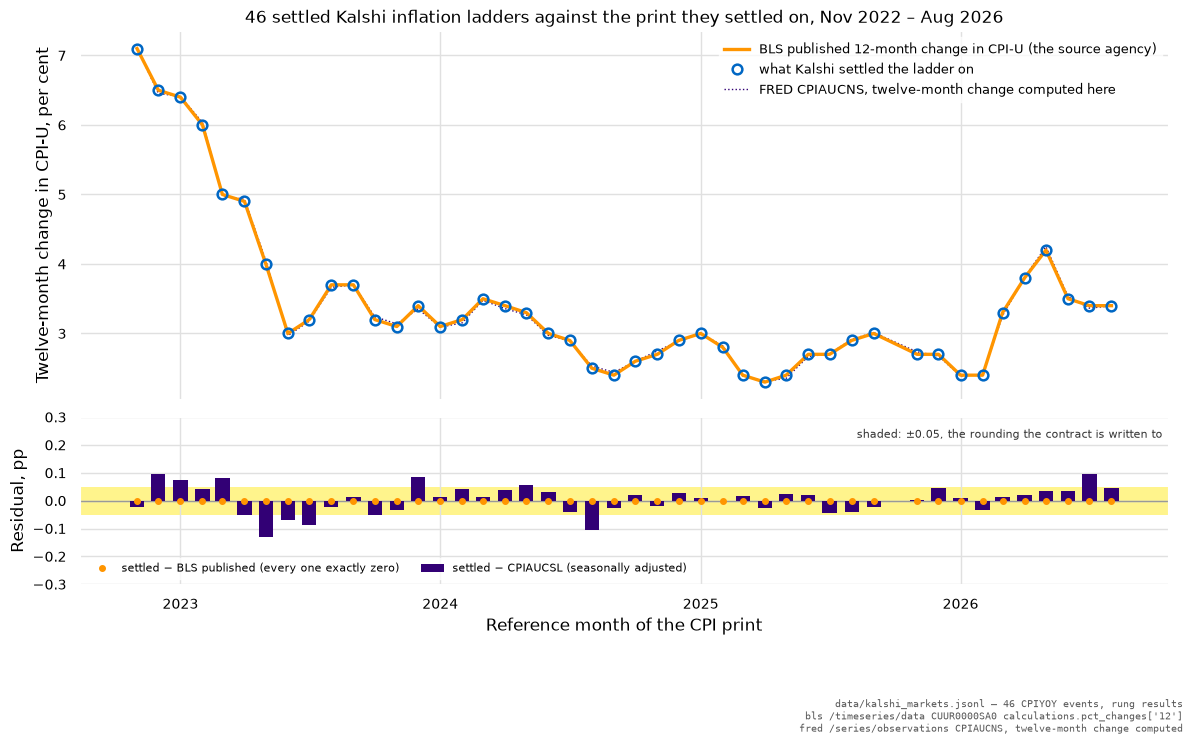

In [10]:
figure, (upper, lower) = pyplot.subplots(
    2, 1, figsize=(12, 7.5), height_ratios=(2.2, 1), sharex=True)

plotted = [r for r in join if r["settled"] is not None and r["bls"] is not None]
stamps = [datetime.strptime(r["month"], "%Y-%m") for r in plotted]
# date2num up front: the axis arguments below are floats as far as the stubs are
# concerned, and converting here keeps that honest.
xs = [date2num(s) for s in stamps]

upper.plot(xs, [r["bls"] for r in plotted], color=ORANGE, lw=2.4, zorder=2,
           label="BLS published 12-month change in CPI-U (the source agency)")
upper.plot(xs, [r["settled"] for r in plotted], color=BLUE, lw=0.0, marker="o",
           markersize=7, mfc="none", mew=1.8, zorder=3,
           label="what Kalshi settled the ladder on")
upper.plot(xs, [r["nsa"] for r in plotted], color=PURPLE, lw=1.0, ls=":", zorder=1,
           label="FRED CPIAUCNS, twelve-month change computed here")
upper.set_ylabel("Twelve-month change in CPI-U, per cent")
upper.set_title("46 settled Kalshi inflation ladders against the print they settled on, "
                "Nov 2022 – Aug 2026", fontsize=12)
upper.legend(loc="upper right", fontsize=9)

# The residual panel is where the series is identified. Against the published
# BLS number every residual is exactly zero, which is why that series is drawn as
# a line of dots rather than as bars: an empty bar chart reads as a broken one.
# Against the seasonally adjusted index the residuals are the seasonal factor.
lower.axhline(0.0, color="0.6", lw=1.0, zorder=1)
# The tick is one tenth of a percentage point, so anything inside the band is
# agreement at the resolution the contract is written to.
lower.axhspan(-0.05, 0.05, color=YELLOW, alpha=0.45, lw=0, zorder=0)
lower.bar(xs, [round(r["settled"] - r["sa"], 3) for r in plotted], width=20,
          color=PURPLE, zorder=2, label="settled − CPIAUCSL (seasonally adjusted)")
lower.plot(xs, [round(r["settled"] - r["bls"], 3) for r in plotted], linestyle="none",
           marker="o", markersize=4, color=ORANGE, zorder=3,
           label="settled − BLS published (every one exactly zero)")
lower.set_ylim(-0.3, 0.3)
lower.set_ylabel("Residual, pp")
lower.set_xlabel("Reference month of the CPI print")
lower.xaxis.set_major_locator(YearLocator())
lower.xaxis.set_major_formatter(DateFormatter("%Y"))
lower.legend(loc="lower left", fontsize=8, ncols=2)
lower.text(0.995, 0.93, "shaded: ±0.05, the rounding the contract is written to",
           transform=lower.transAxes, fontsize=8, va="top", ha="right", alpha=0.8)

figure.tight_layout()
stamp("data/kalshi_markets.jsonl — 46 CPIYOY events, rung results",
      "bls /timeseries/data CUUR0000SA0 calculations.pct_changes['12']",
      "fred /series/observations CPIAUCNS, twelve-month change computed",
      figure=figure)

### The provenance is good, and it is not audited

Two caveats, both measured rather than supposed.

**`settlement_sources` is a URL, and nobody checks it.** It is metadata Kalshi
fills in, not a resolved reference, and on at least one macro series it is
simply wrong: `KXPAYROLLS` — non-farm payrolls, which settle on the Employment
Situation release — points at the **PPI** news release. The contract still
settles correctly, because the contract text and the filed terms PDF govern;
but a pipeline that keyed a join on the settlement URL alone would join
payrolls to the wrong table. Key on the agency, pin the series by agreement,
and treat the URL as a hint.

**The prose still matters at the edges.** `rules_secondary` on the CPI rung
carries a government-shutdown clause that extends the latest expiration by up
to six months, and the gap between `expected_expiration_time` and
`expiration_time` on the live September contract is where that clause lives:
three months of slack on a market that expects to settle the same morning.
Arithmetic resolution is not instant resolution.

In [11]:
by_ticker = {s["ticker"]: s for s in series_rows}
audit = [("KXCPIYOY", "CPI-U, all items"), ("KXCPICOREYOY", "CPI-U less food and energy"),
         ("KXU3", "unemployment rate"), ("KXPAYROLLS", "non-farm payrolls"),
         ("KXPCECORE", "core PCE"), ("KXFED", "the fed funds target"),
         ("KXGDPYEAR", "annual GDP")]
print(f"{'series':16} {'what it settles on':30} {'named source':32} {'release page'}")
for ticker, concept in audit:
    s = by_ticker.get(ticker)
    if s is None:
        continue
    names = ", ".join(n for n in (s["source_names"] or []) if n)[:30]
    urls = (s["source_urls"] or [None])[0] or ""
    tail = urls.split("bls.gov/")[-1] if "bls.gov" in urls else urls.split("//")[-1]
    note = "  ← names the PPI release" if "ppi" in urls.lower() else ""
    print(f"{ticker:16} {concept:30} {names:32} {tail[:34]}{note}")

# The settled corpus contains no open markets at all — the harvest walked
# `status=settled` on the live route and the whole historical tier — so the
# September 2026 event, which is the one section 3 reads, is absent from disk by
# construction. Worth printing rather than assuming: a reader who expects a
# watchlist to be recoverable from `data/` would otherwise find an empty result
# and blame the filter.
print(f"\nKXCPIYOY events on disk: {len(cpi_events)}, of which open: "
      f"{sum(1 for e in cpi_events.values() if any(r['status'] not in ('finalized', 'settled') for r in e['rungs']))}")
print("the live September event is not in the corpus and cannot be; section 3 reads it "
      "off the wire, and section 10 is how you would find it in the first place")

series           what it settles on             named source                     release page
KXCPIYOY         CPI-U, all items               Bureau of Labor Statistics       cpi/
KXCPICOREYOY     CPI-U less food and energy     Bureau of Labor Statistics       cpi/
KXU3             unemployment rate              Bureau of Labor Statistics       news.release/empsit.toc.htm
KXPAYROLLS       non-farm payrolls              BLS                              news.release/ppi.nr0.htm  ← names the PPI release
KXPCECORE        core PCE                       Bureau of Economic Analysis      www.bea.gov/data/income-saving/per
KXFED            the fed funds target           Federal Reserve Board of Gover   www.federalreserve.gov/monetarypol
KXGDPYEAR        annual GDP                     Bureau of Economic Analysis      www.bea.gov/data/gdp/gross-domesti

KXCPIYOY events on disk: 46, of which open: 0
the live September event is not in the corpus and cannot be; section 3 reads it off the wire, and s

## 3. A price is not a probability, and the wedges are measurable

A Kalshi price is a **fee-distorted, capital-locked, one-cent-quantised quote
on a statistic that has not printed yet**. Four wedges sit between it and a
probability, and they do not all point the same way. Three are measurable from
public data and one is not.

The live September inflation ladder is the worked example for all of them: 21
rungs on one number, quoted right now. One call.

In [12]:
LIVE.spend("GET /events/KXCPIYOY-26SEP", "with_nested_markets — 21 live rungs")
live_event = LIVE.reader.event("KXCPIYOY-26SEP", nested=True)
assert live_event is not None
live_rungs = sorted(
    (kalshi.normalise_market(m) for m in (live_event.get("markets") or [])),
    key=lambda m: m["floor_strike"] or 0.0)

print(f"{live_event['event_ticker']} — {live_event['title']}")
print(f"mutually_exclusive {live_event['mutually_exclusive']}   "
      f"series {live_event['series_ticker']}   category {live_event['category']}")
SEP_CLOSE = datetime.fromisoformat(live_rungs[0]["close_time"].replace("Z", "+00:00"))
SEP_EXPIRY = datetime.fromisoformat(live_rungs[0]["expiration_time"].replace("Z", "+00:00"))
print(f"trading closes {SEP_CLOSE:%Y-%m-%d %H:%M} UTC, one minute before the BLS release; "
      f"{(SEP_CLOSE - datetime.now(UTC)).days} days from now")
print(f"latest expiration {SEP_EXPIRY:%Y-%m-%d} — "
      f"{(SEP_EXPIRY - SEP_CLOSE).days} days of slack, which is where the "
      f"government-shutdown clause lives\n")

print(f"{'rung':22} {'strike':>7} {'bid':>5} {'ask':>5} {'mid':>6} {'spread':>7} "
      f"{'rel':>6} {'bid sz':>9} {'ask sz':>9} {'liq':>5} {'volume':>10} {'OI':>9}")
for rung in live_rungs:
    bid, ask = rung["yes_bid"], rung["yes_ask"]
    mid = (bid + ask) / 2.0 if bid is not None and ask is not None else None
    spread = (ask - bid) if bid is not None and ask is not None else None
    rel = (spread / mid) if spread is not None and mid else None
    print(f"{rung['ticker']:22} {rung['floor_strike']:7.1f} "
          f"{bid if bid is not None else float('nan'):5.2f} "
          f"{ask if ask is not None else float('nan'):5.2f} "
          f"{mid if mid is not None else float('nan'):6.3f} "
          f"{spread if spread is not None else float('nan'):7.2f} "
          f"{rel if rel is not None else float('nan'):6.1%} "
          f"{rung['yes_bid_size'] or 0:9,.0f} {rung['yes_ask_size'] or 0:9,.0f} "
          f"{rung['liquidity'] if rung['liquidity'] is not None else float('nan'):5.1f} "
          f"{rung['volume']:10,.0f} {rung['open_interest']:9,.0f}")

two_sided = [r for r in live_rungs
             if (r["yes_bid"] or 0) > 0 and (r["yes_ask"] or 1) < 1]
print(f"\n{len(two_sided)} of {len(live_rungs)} rungs carry a genuine two-sided quote; "
      f"the rest are ask-only at the one-cent floor")
print(f"every rung reports liquidity = "
      f"{sorted({r['liquidity'] for r in live_rungs})} — see below")

KXCPIYOY-26SEP — Inflation in September 2026 (CPI YoY)
mutually_exclusive False   series KXCPIYOY   category Economics
trading closes 2026-10-14 12:29 UTC, one minute before the BLS release; 17 days from now
latest expiration 2027-01-13 — 91 days of slack, which is where the government-shutdown clause lives

rung                    strike   bid   ask    mid  spread    rel    bid sz    ask sz   liq     volume        OI
KXCPIYOY-26SEP-T3.0        3.0  0.97  0.98  0.975    0.01   1.0%     2,334     2,354   0.0     55,003    24,605
KXCPIYOY-26SEP-T3.1        3.1  0.97  0.98  0.975    0.01   1.0%         1     4,520   0.0     35,710    12,253
KXCPIYOY-26SEP-T3.2        3.2  0.96  0.97  0.965    0.01   1.0%         1        99   0.0     23,662     9,810
KXCPIYOY-26SEP-T3.3        3.3  0.95  0.96  0.955    0.01   1.0%         1        95   0.0     15,185    10,263
KXCPIYOY-26SEP-T3.4        3.4  0.91  0.94  0.925    0.03   3.2%         1       166   0.0     31,768    20,736
KXCPIYOY-26SEP-T3.

### Wedge one: the spread, and what it does to an interval

The `liquidity` field in that table is **0.0000 on all 21 rungs**, including
the one with a one-cent spread, eighteen bid levels and 46,000 contracts of
open interest. Polymarket's `liquidityNum` is a real measurement of the wrong
thing — resting bid notional summed across both outcome books, verified to four
figures. Kalshi's is not a measurement at all: it is absent while looking like
a number, so a screen that rejects markets on it rejects the best markets on
the venue.

Depth has to be computed from the book, and Kalshi's book has a shape worth
knowing: there is **no ask list**. `/orderbook` returns two *bid* stacks, one
per outcome, and an ask on YES is a bid on NO at the complement, so
`yes_ask = 1 − max(no price)`. `kalshi.book_depth` does that conversion and
then sums notional within a cent of the touch on each side.

Three books, on the rung that is actually in play, the rung above it, and a
dead one.

In [13]:
BOOK_RUNGS = ("KXCPIYOY-26SEP-T3.6", "KXCPIYOY-26SEP-T3.5", "KXCPIYOY-26SEP-T4.5")
books: dict[str, dict[str, Any]] = {}
for ticker in BOOK_RUNGS:
    LIVE.spend(f"GET /markets/…/orderbook", ticker)
    books[ticker] = kalshi.book_depth(LIVE.reader.orderbook(ticker))

row = {r["ticker"]: r for r in live_rungs}
print(f"{'rung':22} {'bid':>5} {'ask':>5} {'spr':>5} {'bid $1c':>9} {'ask $1c':>9} "
      f"{'levels':>9} {'imbal':>7} {'row liq':>8} {'row OI':>9}")
for ticker in BOOK_RUNGS:
    d, m = books[ticker], row[ticker]
    print(f"{ticker:22} "
          f"{d['yes_bid'] if d['yes_bid'] is not None else float('nan'):5.2f} "
          f"{d['yes_ask'] if d['yes_ask'] is not None else float('nan'):5.2f} "
          f"{d['spread'] if d['spread'] is not None else float('nan'):5.2f} "
          f"{d['bid_depth']:9,.0f} {d['ask_depth']:9,.0f} "
          f"{d['bid_levels']:4}/{d['ask_levels']:<4} "
          f"{d['imbalance'] if d['imbalance'] is not None else float('nan'):7.2f} "
          f"{m['liquidity']:8.1f} {m['open_interest']:9,.0f}")

print("\nthe deepest rung on the venue's flagship macro ladder holds "
      f"${books['KXCPIYOY-26SEP-T3.6']['bid_depth']:,.0f} of bids within a cent of the touch "
      f"and ${books['KXCPIYOY-26SEP-T3.6']['ask_depth']:,.0f} of asks, "
      f"imbalance {books['KXCPIYOY-26SEP-T3.6']['imbalance']:+.2f}")
print("— makers offering, nobody bidding. The research doc measured $217 and −0.82 "
      "on this same rung on 2026-09-26; this run reproduces it.")
print("the $10,000 depth floor the Polymarket work proposed would reject all three.")

rung                     bid   ask   spr   bid $1c   ask $1c    levels   imbal  row liq    row OI
KXCPIYOY-26SEP-T3.6     0.38  0.39  0.01       217     2,062   20/22     -0.81      0.0    46,237
KXCPIYOY-26SEP-T3.5     0.79  0.85  0.06       230     3,225   26/13     -0.87      0.0    34,617
KXCPIYOY-26SEP-T4.5      nan  0.01   nan         0        14    0/15       nan      0.0    10,673

the deepest rung on the venue's flagship macro ladder holds $217 of bids within a cent of the touch and $2,062 of asks, imbalance -0.81
— makers offering, nobody bidding. The research doc measured $217 and −0.82 on this same rung on 2026-09-26; this run reproduces it.
the $10,000 depth floor the Polymarket work proposed would reject all three.


### Wedge two: the fee, whose coefficient the API will not tell you

Every series carries `fee_type` and `fee_multiplier`, and the census below
shows the family is essentially uniform. What the API does **not** carry is the
coefficient, so the wedge cannot be computed from the wire alone: the shape is
public and the constant is documentary. Kalshi's published schedule charges a
quadratic trading fee proportional to `C · p · (1 − p)` with a coefficient of
**0.07**, rounded up to the cent — *taken from the venue's fee documentation,
not from any call made here, and flagged accordingly.* The `fee_multiplier`
field scales it per series, and fourteen series carry a multiplier of **zero**.

The shape is the same as Polymarket's politics fee and the interpretation is
the same too: the fee is largest at even money and vanishes at the extremes, so
it is a **band around the fair price** rather than a level shift, and the band
is widest exactly where a forecast is most uncertain.

In [14]:
print(f"{'fee_type':36} {'series':>7}")
for fee_type, n in Counter(s["fee_type"] for s in series_rows).most_common():
    print(f"{str(fee_type):36} {n:7,}")
print(f"\n{'fee_multiplier':36} {'series':>7}")
for mult, n in Counter(s["fee_multiplier"] for s in series_rows).most_common():
    print(f"{mult!s:36} {n:7,}")
free = [s for s in series_rows if s["fee_multiplier"] == 0]
print(f"\nthe {len(free)} fee-free series, which include three macro ones:")
for s in sorted(free, key=lambda s: s["category"]):
    print(f"  {s['ticker']:22} {s['category'][:12]:12} {s['title'][:44]}")

#: Kalshi's published quadratic coefficient. DOCUMENTED, NOT MEASURED: the API
#: exposes `fee_type` and `fee_multiplier` and no coefficient, so this number
#: comes from the venue's fee schedule rather than from any call in this
#: notebook, and every figure derived from it inherits that provenance.
FEE_COEFFICIENT = 0.07


def fee_band(price: float, coefficient: float = FEE_COEFFICIENT,
             multiplier: float = 1.0) -> float:
    """Width of the no-arbitrage band a quadratic trading fee opens, per contract.

    A round trip crosses the fee twice, so the band is `2 · k · m · p(1−p)`: a
    price inside it cannot be arbitraged against the true probability because the
    fee eats the edge. Whether the schedule charges each side separately is a
    documentation question rather than an API one, so this is an upper bound on
    the band and the honest way to read it.
    """
    return 2.0 * coefficient * multiplier * price * (1.0 - price)


print(f"\n{'price':>6} {'fee per contract':>17} {'as % of stake':>14} "
      f"{'round-trip band':>16} {'vs the 1c tick':>15}")
for price in (0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.95, 0.99):
    fee = FEE_COEFFICIENT * price * (1.0 - price)
    band = fee_band(price)
    print(f"{price:6.2f} {fee:17.4f} {fee / price:14.1%} {band:16.4f} "
          f"{band / 0.01:14.1f}×")

quality_rows = read_rows("kalshi_quality.jsonl")
rel_spreads = sorted(r["median_rel_spread"] for r in quality_rows
                     if r.get("median_rel_spread") is not None)
print(f"\nfor comparison, the median relative spread over the whole life of "
      f"{len(rel_spreads):,} settled markets in the corpus is "
      f"{statistics.median(rel_spreads):.0%}, and the 90th percentile is "
      f"{quantile(rel_spreads, 0.9):.0%}")
print("— so on a typical Kalshi market the spread is an order of magnitude wider "
      "than the fee, and the fee is the small wedge. On the flagship CPI rung, "
      "with a one-cent spread at a mid near 0.39, they are the same size.")

fee_type                              series
quadratic                             14,229
quadratic_with_maker_fees                160
quadratic_with_combo_maker_fees            3

fee_multiplier                        series
1                                     14,359
0.5                                       19
0                                         14

the 14 fee-free series, which include three macro ones:
  KXBTCY                 Crypto       BTC price range EOY
  KXETHY                 Crypto       ETH price EOY 
  KXCITRINI              Economics    Will the Citrini scenario materialize?
  KXGDPYEAR              Economics    Annual GDP
  KXLAYOFFSYINFO         Economics    Tech layoffs
  KXELECTIRAN            Elections    Will Iran hold a presidential election?
  KXNEXTIRANLEADER       Elections    Who will be Khamenei's successor?
  KXTRUMPOUT             Elections    Trump Out As President
  KXPAHLAVIHEAD          Financials   Will Pahlavi lead Iran?
  KXIRANDEMOCRACY    

### Wedge three: the time value of the collateral

A Kalshi position is fully collateralised: a contract that pays $1 needs $1
posted, and the posted dollar earns the holder nothing. A claim settling in τ
years should therefore trade near `p · exp(−rτ)` rather than at `p`, which
biases every long-dated price **downward** and is not an error in the market —
it is the correct price of a non-yielding claim.

The anchor is the Treasury par curve, verified on 2026-09-25 in the research
doc: **3-month 4.24%, 1-year 4.50%, 2-year 4.81%, 3-year 4.94%**. The doc also
records why the literature's constant is not used here — the cited magnitudes
are unsupported by the citation as given, and a direct measurement on
Polymarket could not be narrowed inside [0.55%, 4.95%]. Today's curve is the
defensible anchor.

**And Kalshi's strike ladders make this wedge behave differently from
Polymarket's date ladders, in a way worth being precise about.** Every rung of
`KXCPIYOY-26SEP` settles on the same morning, so the discount is a *single
scalar common to all of them*. It shifts the level of the whole ladder and
cancels out of every difference, ratio and quantile taken across rungs. On a
"by date T" ladder the horizons differ rung by rung, the discount becomes a
gradient, and differencing raw prices mixes that gradient into the interval
mass — which is exactly why `metrics.discount_adjust_ladder` insists on running
first. So: **correct a date ladder before differencing it; a strike ladder needs
correcting only before reading an absolute probability off it.**

At Kalshi's real macro horizon the correction is a rounding error. At the
horizon where its contracts merely exist, it is most of the price.

In [15]:
#: The Treasury par yield curve on 2026-09-25, verified in the research doc. Used
#: as the discount anchor; interpolated flat beyond three years, which is a
#: conservative choice given the curve was rising across the quoted tenors.
TREASURY = {0.25: 0.0424, 1.0: 0.0450, 2.0: 0.0481, 3.0: 0.0494}


def treasury_rate(years: float) -> float:
    """The anchor rate at a horizon, by linear interpolation on the quoted tenors."""
    tenors = sorted(TREASURY)
    if years <= tenors[0]:
        return TREASURY[tenors[0]]
    if years >= tenors[-1]:
        return TREASURY[tenors[-1]]
    for lo, hi in zip(tenors, tenors[1:]):
        if lo <= years <= hi:
            weight = (years - lo) / (hi - lo)
            return TREASURY[lo] + weight * (TREASURY[hi] - TREASURY[lo])
    return TREASURY[tenors[-1]]


HORIZONS: tuple[tuple[str, float], ...] = (
    ("KXCPIYOY-26SEP, the live inflation ladder", (SEP_CLOSE - datetime.now(UTC)).days / 365.25),
    ("KXUSCPIYEAR-28FEB01, inflation in Dec 2027",
     (datetime(2028, 2, 1, tzinfo=UTC) - datetime.now(UTC)).days / 365.25),
    ("the longest horizon in the settled corpus", 798.0 / 365.25),
    ("KXUSCPIYEAR-37FEB01, inflation in Dec 2036",
     (datetime(2037, 2, 1, tzinfo=UTC) - datetime.now(UTC)).days / 365.25),
)
print(f"{'horizon':44} {'years':>6} {'r':>6} {'exp(-rτ)':>9} {'a fair 0.40 trades at':>22}")
for label, years in HORIZONS:
    rate = treasury_rate(years)
    factor = math.exp(-rate * years)
    print(f"{label:44} {years:6.2f} {rate:6.2%} {factor:9.4f} {0.40 * factor:22.4f}")
print("\nso the collateral wedge is worth a fifth of a cent on the September ladder "
      "and sixteen cents on the 2036 one, which is more than the width of most of "
      "that ladder's quotes.")

horizon                                       years      r  exp(-rτ)  a fair 0.40 trades at
KXCPIYOY-26SEP, the live inflation ladder      0.05  4.24%    0.9980                 0.3992
KXUSCPIYEAR-28FEB01, inflation in Dec 2027     1.35  4.61%    0.9398                 0.3759
the longest horizon in the settled corpus      2.18  4.83%    0.8998                 0.3599
KXUSCPIYEAR-37FEB01, inflation in Dec 2036    10.35  4.94%    0.5997                 0.2399

so the collateral wedge is worth a fifth of a cent on the September ladder and sixteen cents on the 2036 one, which is more than the width of most of that ladder's quotes.


### All three together: the overround on a partition

On the survival ladder of section 4 the prices sum to one *by construction*, so
the sum is not a test. On Kalshi's other multi-outcome shape it is the test.
A `mutually_exclusive` event — Kalshi's `between` buckets — partitions an
outcome space, exactly one rung pays, and the prices must therefore sum to
**one, less the collateral discount**. Anything above that is the venue's
overround, and it is the bookmaker's number under another name.

`KXRATECUTCOUNT-25DEC31` is the case: fifteen rungs on how many times the Fed
would cut in 2025, from "exactly 0" to "14 or more", 20.5m contracts of volume,
and it settled on **exactly 3**. Every rung has a stored daily path, so the sum
can be taken on 154 days when all fifteen carried a two-sided quote.

One caveat on the arithmetic below, and it is not a small one: a candle's
`yes_bid` is the bid at the **close of that day**, so fifteen of them are only
approximately simultaneous. A sum built from them is a day-grain estimate of
something that has to be executed in one instant across fifteen legs.

In [16]:
PARTITION = "KXRATECUTCOUNT-25DEC31"
partition_markets = {}
partition_paths: dict[str, list[dict[str, Any]]] = {}
for line in (DATA / "kalshi_markets.jsonl").open():
    row = json.loads(line)
    if row["event_ticker"] == PARTITION:
        partition_markets[row["ticker"]] = row
for line in (DATA / "kalshi_candles.jsonl").open():
    row = json.loads(line)
    if row["event_ticker"] == PARTITION:
        partition_paths[row["ticker"]] = row["candles"]

# The per-rung titles read "Will the Fed cut rates 9 times?", one per bucket, so
# the SERIES title is the one that names the question the partition covers.
print(f"{PARTITION} — {by_ticker['KXRATECUTCOUNT']['title']}, "
      f"settling against {by_ticker['KXRATECUTCOUNT']['source_names']}")
print(f"{len(partition_markets)} mutually exclusive rungs, "
      f"{sum(m['volume'] for m in partition_markets.values()):,.0f} contracts of volume, "
      f"settled on "
      f"{next(m['yes_sub_title'] for m in partition_markets.values() if m['result'] == 'yes')!r}\n")

quotes: dict[str, dict[str, tuple[float, float]]] = defaultdict(dict)
for ticker, candles in partition_paths.items():
    for candle in candles:
        if candle.get("yes_bid") is not None and candle.get("yes_ask") is not None:
            quotes[candle["date"]][ticker] = (candle["yes_bid"], candle["yes_ask"])

complete = [(day, sum(b for b, _ in q.values()), sum(a for _, a in q.values()))
            for day, q in sorted(quotes.items()) if len(q) == len(partition_markets)]
sum_bid = [b for _, b, _ in complete]
sum_ask = [a for _, _, a in complete]
sum_mid = [(b + a) / 2.0 for _, b, a in complete]
print(f"{len(complete)} days with all {len(partition_markets)} rungs two-sided")
print(f"  Σ bid   median {statistics.median(sum_bid):.3f}   max {max(sum_bid):.3f}")
print(f"  Σ mid   median {statistics.median(sum_mid):.3f}")
print(f"  Σ ask   median {statistics.median(sum_ask):.3f}   min {min(sum_ask):.3f}")

# The no-arbitrage reference is not 1.0 but exp(-r*tau): the payout is a year away
# and the collateral earns nothing in the meantime.
horizon_years = 1.0
reference = math.exp(-treasury_rate(horizon_years) * horizon_years)
print(f"\nthe no-arbitrage reference at a one-year horizon is exp(−rτ) = "
      f"{reference:.3f}, not 1.000")
print(f"so the mid-based overround is "
      f"{statistics.median(sum_mid) - reference:+.3f} on the dollar")

buy_below = [row for row in complete if row[2] < 1.0]
sell_above = [row for row in complete if row[1] > 1.0]
fee_on_book = sum(fee_band(p, multiplier=1.0) / 2.0 for p in (0.5, *[0.05] * 14))
print(f"\ndays you could BUY the whole partition for less than the $1 it pays: "
      f"{len(buy_below)} of {len(complete)} — never")
print(f"days you could SELL the whole partition for more than $1: "
      f"{len(sell_above)} of {len(complete)}, "
      f"largest gross credit {max(sum_bid) - 1.0:.3f}")
print(f"one-way fee across fifteen legs, at the documented coefficient and a "
      f"plausible price vector: about {fee_on_book:.3f}")
print(f"\nSo the overround is real and it is one-sided. You can never assemble the "
      f"book below par. You could, on {len(sell_above) / len(complete):.0%} of days, "
      f"disassemble it above par — by five cents at the very best, against a "
      f"one-way fee across fifteen legs of about six, which is larger than the "
      f"credit; and that is before the fifteen touch sizes, and while treating "
      f"fifteen daily closing bids as one instant. The honest reading is not "
      f"'there was an arbitrage'. It is that **the mid on a Kalshi partition sits "
      f"about twelve cents above where the discounted arithmetic puts it**, seven "
      f"of them above a naive 1.00 — the gap is the makers' spread rather than a "
      f"mispricing, and any probability read off those mids has to be normalised "
      f"before it means anything.")

KXRATECUTCOUNT-25DEC31 — Number of rate cuts, settling against ['Federal Reserve']
15 mutually exclusive rungs, 20,625,394 contracts of volume, settled on 'Exactly 3 cuts'

154 days with all 15 rungs two-sided
  Σ bid   median 0.980   max 1.050
  Σ mid   median 1.075
  Σ ask   median 1.160   min 1.110

the no-arbitrage reference at a one-year horizon is exp(−rτ) = 0.956, not 1.000
so the mid-based overround is +0.119 on the dollar

days you could BUY the whole partition for less than the $1 it pays: 0 of 154 — never
days you could SELL the whole partition for more than $1: 26 of 154, largest gross credit 0.050
one-way fee across fifteen legs, at the documented coefficient and a plausible price vector: about 0.064

So the overround is real and it is one-sided. You can never assemble the book below par. You could, on 17% of days, disassemble it above par — by five cents at the very best, against a one-way fee across fifteen legs of about six, which is larger than the credit; and that is 

### Wedge four: the one that cannot be measured

The fourth is **quote age**, and `metrics.NOT_COMPUTABLE` names it rather than
approximating it: no venue timestamps an order-book level, so the age of the
quote you are about to hit is unknowable from a single read. Kalshi is no
exception, and it matters more here than the fee does. Most of the twenty-one
rungs above are ask-only at the one-cent floor; whether those asks were placed
this morning or in June is not in the payload.

The figure puts the three measurable wedges on one page, at the scale they
actually operate.

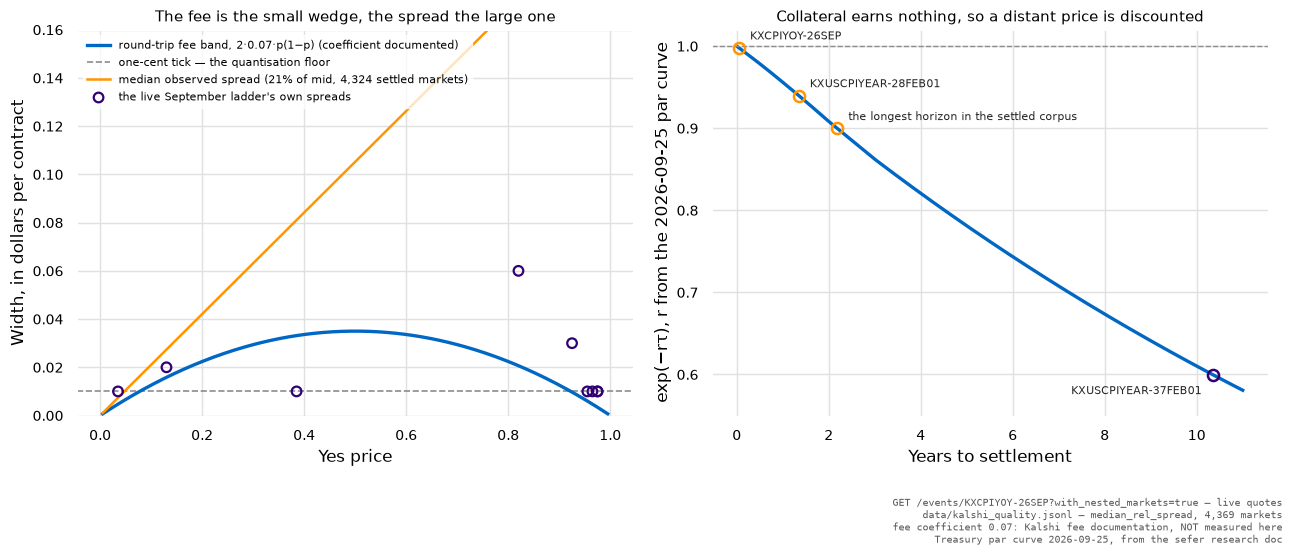

In [17]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.6))

grid = numpy.linspace(0.005, 0.995, 400)
left.plot(grid, [fee_band(float(p)) for p in grid], color=BLUE, lw=2.4,
          label=f"round-trip fee band, 2·{FEE_COEFFICIENT}·p(1−p) (coefficient documented)")
left.axhline(0.01, color="0.55", lw=1.2, ls="--", zorder=1,
             label="one-cent tick — the quantisation floor")
median_rel = statistics.median(rel_spreads)
left.plot(grid, [median_rel * float(p) for p in grid], color=ORANGE, lw=1.8, ls="-",
          label=f"median observed spread ({median_rel:.0%} of mid, {len(rel_spreads):,} settled markets)")
live_mid = [( (r["yes_bid"] + r["yes_ask"]) / 2.0, r["yes_ask"] - r["yes_bid"])
            for r in live_rungs
            if r["yes_bid"] is not None and r["yes_ask"] is not None and r["yes_bid"] > 0]
left.scatter([m for m, _ in live_mid], [s for _, s in live_mid], s=48, zorder=4,
             facecolor="none", edgecolor=PURPLE, linewidth=1.6,
             label="the live September ladder's own spreads")
left.set_xlabel("Yes price")
left.set_ylabel("Width, in dollars per contract")
left.set_title("The fee is the small wedge, the spread the large one", fontsize=11)
left.set_ylim(0, 0.16)
left.legend(loc="upper left", fontsize=8)

years = numpy.linspace(0.02, 11.0, 400)
factors = [math.exp(-treasury_rate(float(t)) * float(t)) for t in years]
right.plot(years, factors, color=BLUE, lw=2.4)
right.axhline(1.0, color="0.55", lw=1.0, ls="--")
for label, horizon in HORIZONS:
    factor = math.exp(-treasury_rate(horizon) * horizon)
    right.plot([horizon], [factor], marker="o", markersize=8, mfc="none", mew=1.8,
               color=ORANGE if horizon < 3 else PURPLE, zorder=4)
    # The ten-year marker sits at the right edge, so its label has to run back
    # into the axes rather than off the page.
    far = horizon > 8
    right.annotate(label.split(",")[0], (horizon, factor),
                   textcoords="offset points",
                   xytext=(-8 if far else 8, 6 if horizon < 3 else -14),
                   ha="right" if far else "left", fontsize=8, alpha=0.85)
right.set_xlabel("Years to settlement")
right.set_ylabel("exp(−rτ), r from the 2026-09-25 par curve")
right.set_title("Collateral earns nothing, so a distant price is discounted", fontsize=11)
right.set_ylim(0.55, 1.02)

figure.tight_layout()
stamp("GET /events/KXCPIYOY-26SEP?with_nested_markets=true — live quotes",
      "data/kalshi_quality.jsonl — median_rel_spread, 4,369 markets",
      "fee coefficient 0.07: Kalshi fee documentation, NOT measured here",
      "Treasury par curve 2026-09-25, from the sefer research doc",
      figure=figure)

## 4. The ladder is a distribution — over a number, and over a date

This is the idea the whole directory is organised around, and Kalshi is where
it is cleanest. A row of *"X happens by date T"* markets is a **cumulative
distribution over the resolution date**: adjacent rungs difference into the
probability mass falling in each window, exactly as an option strike ladder
differences into a density over price. Kalshi has those, and section 4.3 works
one.

But Kalshi's native macro shape is the **same idea one axis over**. A
`greater`-strike ladder on a statistic — `KXCPIYOY-26SEP` at T3.0, T3.1 … T5.0
— is a **survival function** over the *value* of the number:
`S(k) = P(X > k)`, weakly decreasing in k, and `−ΔS` is the probability mass in
each tenth. It is a density over the September CPI print, quoted, twenty-one
rungs wide. That is not an analogy with an option strike ladder; it is the same
construction, and Kalshi states the strike in a typed numeric field so no
parsing is needed to recover it.

Three properties follow, and each is a test no single market can support:

* **monotonicity** — `S` must not rise with the strike, because "above 3.6" is a
  subset of "above 3.5". A rise is incoherence.
* **non-negative interval mass** — differencing must not produce negative mass.
* **exhaustiveness** — the mass between the rungs plus the two tails must be
  one, so the ladder says how much of the question it prices at all.

And one property the ladder gives that a single market never can: the **implied
quantile**. Where the survival curve crosses 0.5 is the market's median for the
number itself.

In [18]:
def survival_ladder(rungs: Sequence[dict[str, Any]], price: str = "mid"
                    ) -> list[dict[str, float | str]]:
    """Strike, quote and executable bounds for each two-sided rung, in strike order.

    `price` picks the point estimate, but both ends are carried: an interval's
    mass can only be *bought* at one price and *sold* at another, and reporting a
    single number for it hides the only wedge on this venue that is larger than
    the fee.
    """
    out: list[dict[str, float | str]] = []
    for rung in sorted(rungs, key=lambda r: r["floor_strike"] or 0.0):
        bid, ask = rung["yes_bid"], rung["yes_ask"]
        if bid is None or ask is None or rung["floor_strike"] is None:
            continue
        out.append({"ticker": rung["ticker"], "x": float(rung["floor_strike"]),
                    "bid": float(bid), "ask": float(ask), "mid": (bid + ask) / 2.0})
    return out


def interval_mass(ladder: Sequence[dict[str, float | str]]
                  ) -> list[dict[str, float | str]]:
    """The probability mass in each strike interval, with the band it trades in.

    For a survival ladder the mass in `(a, b]` is `S(a) − S(b)`. Buying it means
    buying the low rung at its ask and selling the high rung at its bid, so the
    cost is `ask(a) − bid(b)`; selling it is `bid(a) − ask(b)`. Those two bracket
    the honest answer, and the point estimate from mids sits between them.
    """
    out: list[dict[str, float | str]] = []
    for lo, hi in zip(ladder, ladder[1:]):
        out.append({
            "lo": lo["x"], "hi": hi["x"],
            "mass": float(lo["mid"]) - float(hi["mid"]),
            "buy": float(lo["ask"]) - float(hi["bid"]),
            "sell": float(lo["bid"]) - float(hi["ask"]),
        })
    return out


live_ladder = survival_ladder(live_rungs)
live_mass = interval_mass(live_ladder)
tail_below = 1.0 - float(live_ladder[0]["mid"])
tail_above = float(live_ladder[-1]["mid"])

print(f"KXCPIYOY-26SEP as a survival function over the September CPI print, "
      f"{len(live_ladder)} two-sided rungs\n")
print(f"{'interval':16} {'mass (mids)':>12} {'sell at':>9} {'buy at':>9} "
      f"{'band':>7}  what you would be buying")
lowest, highest = float(live_ladder[0]["x"]), float(live_ladder[-1]["x"])
print(f"{f'<= {lowest:.1f}':16} {tail_below:12.3f} "
      f"{'-':>9} {'-':>9} {'-':>7}  the lower tail, not priced by any rung")
for row in live_mass:
    band = float(row["buy"]) - float(row["sell"])
    label = f"({row['lo']:.1f}, {row['hi']:.1f}]"
    print(f"{label:16} {row['mass']:12.3f} {row['sell']:9.3f} {row['buy']:9.3f} "
          f"{band:7.3f}  a print of exactly {row['hi']:.1f}")
print(f"{f'>  {highest:.1f}':16} {tail_above:12.3f} "
      f"{'-':>9} {'-':>9} {'-':>7}  the upper tail")
print(f"\nmass in the rungs {sum(float(r['mass']) for r in live_mass):.3f} "
      f"+ lower tail {tail_below:.3f} + upper tail {tail_above:.3f} = "
      f"{sum(float(r['mass']) for r in live_mass) + tail_below + tail_above:.3f}")
print("— which sums to one by construction, so on a strike ladder the sum is not a "
      "test. Monotonicity and the sign of each mass are the tests.")

monotone = all(float(a["mid"]) >= float(b["mid"]) for a, b in zip(live_ladder, live_ladder[1:]))
arbitrage = [(a["ticker"], b["ticker"]) for a, b in zip(live_ladder, live_ladder[1:])
             if float(b["bid"]) > float(a["ask"])]
print(f"\nmonotone on mids: {monotone};  negative masses: "
      f"{sum(1 for r in live_mass if float(r['mass']) < 0)};  "
      f"tradeable violations: {len(arbitrage)}")

crossing = [(float(a["x"]), float(a["mid"]), float(b["x"]), float(b["mid"]))
            for a, b in zip(live_ladder, live_ladder[1:])
            if float(a["mid"]) >= 0.5 >= float(b["mid"])]
if crossing:
    x0, p0, x1, p1 = crossing[0]
    median_x = x0 + (x1 - x0) * (p0 - 0.5) / (p0 - p1)
    print(f"\nimplied median print: {median_x:.2f}%, interpolating between "
          f"S({x0:.1f})={p0:.3f} and S({x1:.1f})={p1:.3f}")
    print(f"the previous print, August 2026, was {bls_published.get('2026-08', float('nan')):.1f}% "
          f"— so the market's median is a {median_x - bls_published.get('2026-08', median_x):+.2f}pp move")
heaviest = max(live_mass, key=lambda r: float(r["mass"]))
print(f"modal tenth: ({heaviest['lo']:.1f}, {heaviest['hi']:.1f}] at "
      f"{heaviest['mass']:.1%}, tradeable between {heaviest['sell']:.1%} and "
      f"{heaviest['buy']:.1%}")
print("\nthat band is the whole lesson of section 3 in one line: the most informative "
      "number this ladder produces is known to about three cents, and no single "
      "quote on the venue tells you that.")

KXCPIYOY-26SEP as a survival function over the September CPI print, 21 two-sided rungs

interval          mass (mids)   sell at    buy at    band  what you would be buying
<= 3.0                  0.025         -         -       -  the lower tail, not priced by any rung
(3.0, 3.1]              0.000    -0.010     0.010   0.020  a print of exactly 3.1
(3.1, 3.2]              0.010     0.000     0.020   0.020  a print of exactly 3.2
(3.2, 3.3]              0.010     0.000     0.020   0.020  a print of exactly 3.3
(3.3, 3.4]              0.030     0.010     0.050   0.040  a print of exactly 3.4
(3.4, 3.5]              0.105     0.060     0.150   0.090  a print of exactly 3.5
(3.5, 3.6]              0.435     0.400     0.470   0.070  a print of exactly 3.6
(3.6, 3.7]              0.255     0.240     0.270   0.030  a print of exactly 3.7
(3.7, 3.8]              0.095     0.080     0.110   0.030  a print of exactly 3.8
(3.8, 3.9]              0.030     0.020     0.040   0.020  a print of exac

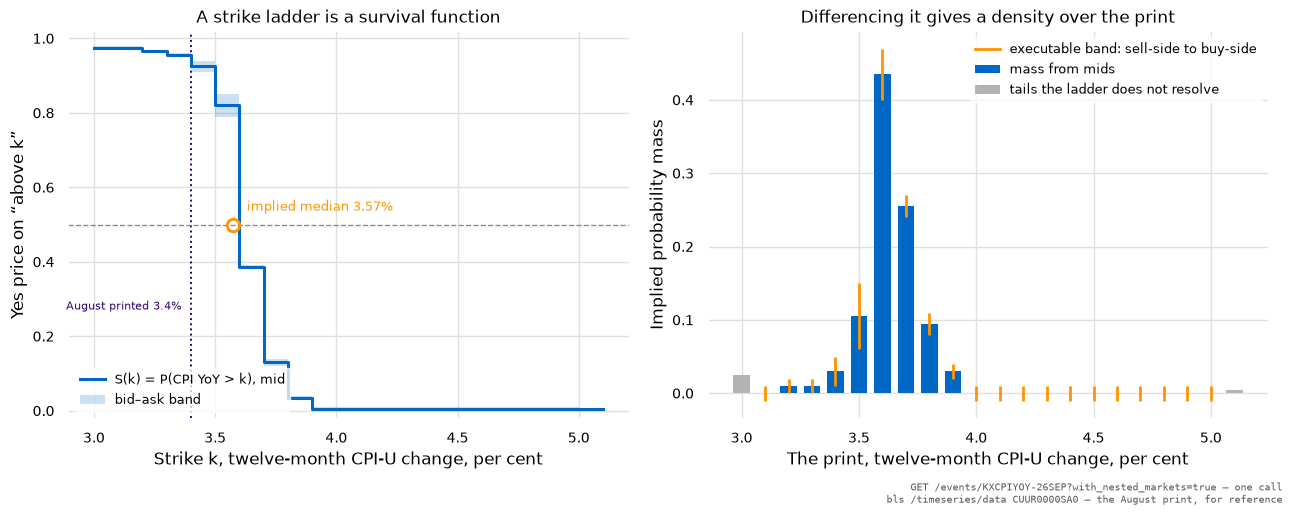

In [19]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.2))

xs = [float(r["x"]) for r in live_ladder]
left.step([*xs, xs[-1] + 0.1], [*[float(r["mid"]) for r in live_ladder], float(live_ladder[-1]["mid"])],
          where="post", color=BLUE, lw=2.2, label="S(k) = P(CPI YoY > k), mid")
left.fill_between(xs, [float(r["bid"]) for r in live_ladder],
                  [float(r["ask"]) for r in live_ladder], step="post",
                  color=BLUE, alpha=0.20, lw=0, label="bid–ask band")
left.axhline(0.5, color="0.55", lw=1.0, ls="--")
if crossing:
    left.plot([median_x], [0.5], marker="o", markersize=9, mfc="none", mew=2.0,
              color=ORANGE, zorder=4)
    left.annotate(f"implied median {median_x:.2f}%", (median_x, 0.5),
                  textcoords="offset points", xytext=(10, 10), fontsize=9, color=ORANGE)
august = bls_published.get("2026-08")
if august is not None:
    left.axvline(august, color=PURPLE, lw=1.4, ls=":", zorder=1)
    left.annotate(f"August printed {august:.1f}%", (august, 0.28),
                  textcoords="offset points", xytext=(-7, 0), fontsize=8,
                  ha="right", va="center", color=PURPLE)
left.set_xlabel("Strike k, twelve-month CPI-U change, per cent")
left.set_ylabel("Yes price on “above k”")
left.set_title("A strike ladder is a survival function", fontsize=12)
left.set_ylim(-0.02, 1.02)
left.legend(loc="lower left", fontsize=9)

# One bar per PRINTED TENTH, placed at the value that would print, not at the
# midpoint of the interval: the mass in (3.5, 3.6] is the market's probability on
# a print of exactly 3.6, and putting the bar at 3.55 hides that.
centres = [float(r["hi"]) for r in live_mass]
masses = [float(r["mass"]) for r in live_mass]
right.bar(centres, masses, width=0.07, color=BLUE, zorder=2, label="mass from mids")
# Whiskers, not error bars: the two ends are the prices at which the interval can
# actually be sold and bought, which is a wider and more honest object than a
# confidence interval.
for row, centre in zip(live_mass, centres):
    right.plot([centre, centre], [float(row["sell"]), float(row["buy"])],
               color=ORANGE, lw=2.0, solid_capstyle="butt", zorder=3)
right.plot([], [], color=ORANGE, lw=2.0, label="executable band: sell-side to buy-side")
right.bar([xs[0]], [tail_below], width=0.07, color="0.7", zorder=2,
          label="tails the ladder does not resolve")
right.bar([xs[-1] + 0.1], [tail_above], width=0.07, color="0.7", zorder=2)
right.set_xlabel("The print, twelve-month CPI-U change, per cent")
right.set_ylabel("Implied probability mass")
right.set_title("Differencing it gives a density over the print", fontsize=12)
right.legend(loc="upper right", fontsize=9)

figure.tight_layout()
stamp("GET /events/KXCPIYOY-26SEP?with_nested_markets=true — one call",
      "bls /timeseries/data CUUR0000SA0 — the August print, for reference",
      figure=figure)

### 4.1 The same ladder, over its life, with the answer known

The live ladder shows the shape. A settled one shows whether the shape was any
good, and `KXCPIYOY-25APR` — inflation in April 2025 — is the right case:
ten rungs from 2.2 to 3.1, all ten with a stored daily path, two months of
life, 11.2m contracts of volume — which section 6 revalues, because a contract
count is not a dollar figure — and a print that is now a matter of record.

Two mechanical points before the numbers, both of them traps.

**Coherence must be scored on a synchronous snapshot, and `last_price` is not
one.** On a settled event every rung reports the price of *its own* final
trade, which after settlement is pinned to 0 or 1 and may be months from its
neighbour's. Scoring the ladder on last prices manufactures violations that
never existed in the book — `kalshi.snapshot` takes the last **mid** at or
before a chosen date instead, and the mid exists on the 45% of days with no
trade, which is exactly what a synchronous read needs.

**The rungs of a settled ladder are not the rungs it was listed with.** Kalshi
adds strikes as the distribution moves, so a snapshot early in the life has
fewer rungs than one late in it. That is visible below and it is the reason the
density is drawn per snapshot rather than as one surface.

In [20]:
APRIL = "KXCPIYOY-25APR"
april_paths: dict[str, list[dict[str, Any]]] = {}
for line in (DATA / "kalshi_candles.jsonl").open():
    row = json.loads(line)
    if row["event_ticker"] == APRIL:
        april_paths[row["ticker"]] = row["candles"]
april_markets = [m for m in markets_by_event[APRIL] if m["ticker"] in april_paths]
april_truth = cpi_events[APRIL]

print(f"{APRIL}: {len(april_markets)} rungs with stored paths, "
      f"{sum(len(p) for p in april_paths.values())} daily candles")
print(f"settled on {april_truth['stated']!r}; the rung boundary brackets "
      f"({april_truth['yes_max']:.1f}, {april_truth['no_min']:.1f}] -> "
      f"{april_truth['bracketed']:.1f}; BLS published "
      f"{bls_published.get('2025-04', float('nan')):.1f}\n")

SNAPSHOTS = ("2025-03-20", "2025-04-10", "2025-05-12")
april_ladders: dict[str, kalshi.Ladder] = {}
for at in SNAPSHOTS:
    built = kalshi.ladder_at(APRIL, april_markets, april_paths, at, field="mid")
    if built is not None:
        april_ladders[at] = built

print(f"{'snapshot':12} {'rungs':>6} {'monotone':>9} {'neg mass':>9} {'mass':>7} "
      f"{'implied median':>15} {'realised':>9}")
for at, ladder in april_ladders.items():
    coherence = ladder.coherence()
    median = ladder.implied_quantile(0.5)
    print(f"{at:12} {coherence['n_rungs']:6} {str(coherence['monotone']):>9} "
          f"{coherence['n_violations']:9} {coherence['implied_mass']:7.3f} "
          f"{median if median is not None else float('nan'):15.3f} "
          f"{april_truth['bracketed']:9.1f}")

print(f"\nand the density at each snapshot, mass per tenth:")
print(f"{'interval':14} " + " ".join(f"{at[5:]:>10}" for at in april_ladders))
intervals = sorted({(d["lo"], d["hi"]) for ladder in april_ladders.values()
                    for d in ladder.differences()})
for lo, hi in intervals:
    cells = []
    for ladder in april_ladders.values():
        found = next((d for d in ladder.differences()
                      if abs(d["lo"] - lo) < 1e-9 and abs(d["hi"] - hi) < 1e-9), None)
        cells.append(f"{found['mass']:10.3f}" if found else f"{'—':>10}")
    marker = "  ← realised" if abs(hi - april_truth["bracketed"]) < 1e-9 else ""
    print(f"({lo:.1f}, {hi:.1f}]   " + " ".join(cells) + marker)

realised_mass = []
for at, ladder in april_ladders.items():
    found = next((d for d in ladder.differences()
                  if abs(d["hi"] - april_truth["bracketed"]) < 1e-9), None)
    realised_mass.append((at, found["mass"] if found else float("nan")))
print(f"\nmass on the tenth that happened: "
      + ", ".join(f"{at} {m:.1%}" for at, m in realised_mass))
print("so the ladder's median was 0.15pp too high for seven weeks and came down to "
      "the right neighbourhood in the last week — and even on the day before the "
      "release it put more weight on the tenth above the answer than on the answer.")
print("That is what a good forward distribution looks like on this venue: "
      "informative, and nowhere near certain.")

KXCPIYOY-25APR: 10 rungs with stored paths, 523 daily candles
settled on '2.30'; the rung boundary brackets (2.2, 2.3] -> 2.3; BLS published 2.3

snapshot      rungs  monotone  neg mass    mass  implied median  realised
2025-03-20       10      True         0   0.835           2.470       2.3
2025-04-10       10     False         1   0.940           2.465       2.3
2025-05-12       10      True         0   0.885           2.329       2.3

and the density at each snapshot, mass per tenth:
interval            03-20      04-10      05-12
(2.2, 2.3]        0.085      0.025      0.290  ← realised
(2.3, 2.4]        0.135      0.140      0.340
(2.4, 2.5]        0.235      0.445      0.160
(2.5, 2.6]        0.185      0.270      0.050
(2.6, 2.7]        0.090      0.055      0.020
(2.7, 2.8]        0.090      0.005      0.005
(2.8, 2.9]        0.005     -0.005      0.015
(2.9, 3.0]        0.005      0.005      0.000
(3.0, 3.1]        0.005      0.000      0.005

mass on the tenth that happened:

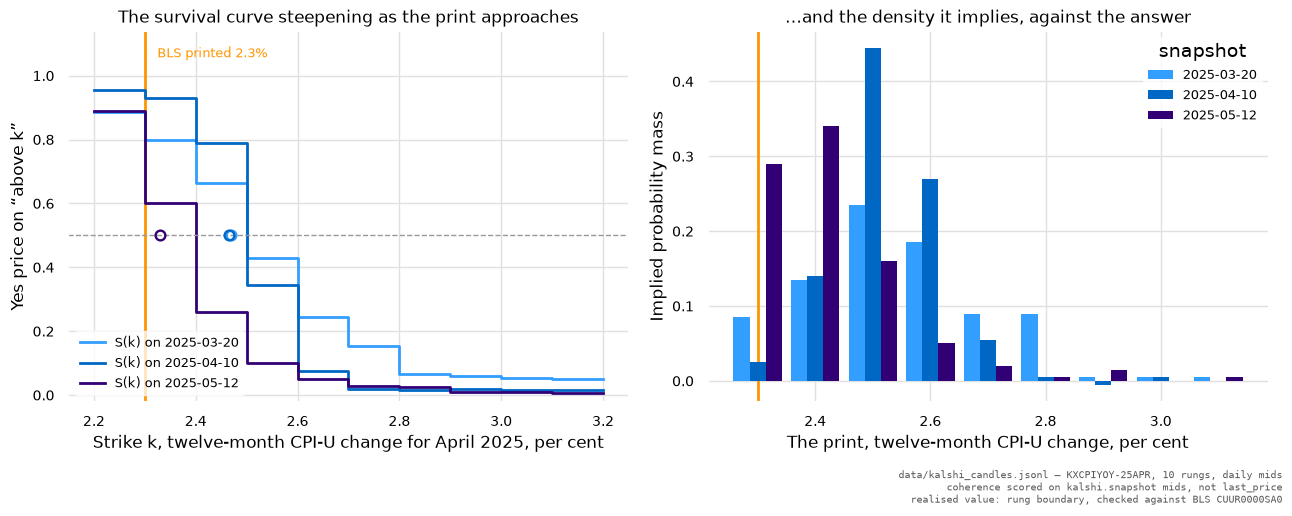

In [21]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.2))

shades = (PALE, BLUE, PURPLE)
for (at, ladder), shade in zip(april_ladders.items(), shades):
    left.step([*ladder.xs, ladder.xs[-1] + 0.1], [*ladder.ps, ladder.ps[-1]],
              where="post", color=shade, lw=2.0, label=f"S(k) on {at}")
    median = ladder.implied_quantile(0.5)
    if median is not None:
        left.plot([median], [0.5], marker="o", markersize=7, mfc="none", mew=1.7,
                  color=shade, zorder=4)
left.axhline(0.5, color="0.6", lw=1.0, ls="--")
left.axvline(april_truth["bracketed"], color=ORANGE, lw=2.0, zorder=1)
# Above the curves rather than across them: at every interesting y the three
# survival steps are in the way.
left.set_ylim(-0.02, 1.14)
left.annotate(f"BLS printed {april_truth['bracketed']:.1f}%",
              (april_truth["bracketed"], 1.07), textcoords="offset points",
              xytext=(9, 0), fontsize=9, va="center", color=ORANGE)
left.set_xlabel("Strike k, twelve-month CPI-U change for April 2025, per cent")
left.set_ylabel("Yes price on “above k”")
left.set_title("The survival curve steepening as the print approaches", fontsize=12)
left.legend(loc="lower left", fontsize=9)

# As in 4.0, one bar per printed tenth at the value that would print, the three
# snapshots offset around it so the same tenth can be read across dates.
width = 0.028
for offset, ((at, ladder), shade) in enumerate(zip(april_ladders.items(), shades)):
    diffs = ladder.differences()
    centres = [d["hi"] + (offset - 1) * width for d in diffs]
    right.bar(centres, [d["mass"] for d in diffs], width=width, color=shade,
              label=at, zorder=2)
right.axvline(april_truth["bracketed"], color=ORANGE, lw=2.0, zorder=1)
right.set_xlabel("The print, twelve-month CPI-U change, per cent")
right.set_ylabel("Implied probability mass")
right.set_title("…and the density it implies, against the answer", fontsize=12)
right.legend(loc="upper right", fontsize=9, title="snapshot")

figure.tight_layout()
stamp(f"data/kalshi_candles.jsonl — {APRIL}, {len(april_markets)} rungs, daily mids",
      "coherence scored on kalshi.snapshot mids, not last_price",
      "realised value: rung boundary, checked against BLS CUUR0000SA0",
      figure=figure)

### 4.2 The other axis — a row of deadlines

Kalshi also lists the shape the Polymarket work is built around: a set of
*"…before date T"* markets over one question, which is a **cumulative
distribution over the resolution date**. `kalshi.ladder_shape` distinguishes it
from a partition by requiring the cumulative wording in `yes_sub_title` on a
majority of rungs, because distinct close times alone are not evidence — a set
of "will senator X vote for Y" markets closes on fourteen different days and is
a partition over people, not a distribution over dates.

The best-funded one in the corpus is `KXHORMUZNORM-26MAR17`: **"will the 7-day
moving average of transit calls through the Strait of Hormuz, as reported by the
IMF PortWatch, be above 60 before <date>"**, eleven rungs from 1 April to
1 September 2026, 33.4m contracts of volume, every rung settled **no**.
Traffic never returned to normal.

Keep that market in mind for section 8. It is a question *about a war* that is
listable in the United States, because what it actually references is a shipping
statistic.

Three mechanical points, and the third is the one that bites.

**The x axis is the date in the rung's label, not its `close_time`.** When the
event resolves, every rung that has not yet elapsed is closed early at the same
instant, so their close times collapse onto one value and differencing them
produces nonsense. `kalshi.label_date` reads the intended date out of
"Before Aug 15, 2026" instead.

**The rungs differ in horizon, so the discount is a gradient** — this is the
case where `metrics.discount_adjust_ladder` has to run before anything else,
unlike the strike ladder in 4.1.

**Elapsed rungs must be dropped.** A rung whose deadline has passed sits at
0.00–0.01 forever and contributes a negative interval mass of a tick, which is
the only "incoherence" most of these ladders have. Filtering to live rungs is
the difference between a ladder that fails the monotonicity test and one that
passes it.

In [22]:
hormuz = next(json.loads(line) for line in (DATA / "kalshi_ladder_paths.jsonl").open()
              if json.loads(line)["event_ticker"] == "KXHORMUZNORM-26MAR17")
print(f"{hormuz['event_ticker']} — {hormuz['title']}")
print(f"{hormuz['volume']:,.0f} contracts of volume across "
      f"{len(hormuz['rungs'])} rungs\n")
print(f"{'rung':34} {'deadline':13} {'result':>7} {'volume':>12} {'path':>5} {'first day':>11}")
for rung in sorted(hormuz["rungs"], key=lambda r: kalshi.label_date(r["label"]) or 0):
    path = hormuz["paths"].get(rung["ticker"]) or []
    print(f"{rung['ticker']:34} {rung['label']:13} {rung['result']:>7} "
          f"{rung['volume']:12,.0f} {len(path):5} {path[0]['date'] if path else '—':>11}")
print("\nnote the first days: rungs are ADDED as the front ones elapse, so the "
      "ladder is re-issued rather than fixed, and a snapshot's rung count is a "
      "property of the date you take it on.")

# Market-shaped records for the ladder builders. The label is the only place the
# intended deadline appears, so it is carried as `yes_sub_title` where
# `kalshi.build_ladder` looks for it.
hormuz_markets = [{"ticker": r["ticker"], "yes_sub_title": r["label"],
                   "strike_type": None, "floor_strike": None, "cap_strike": None,
                   "close_time": None} for r in hormuz["rungs"]]

DATE_SNAPSHOTS = ("2026-03-20", "2026-04-20", "2026-05-20", "2026-06-20", "2026-07-20")
print(f"\n{'snapshot':12} {'rungs':>6} {'live':>5} {'monotone':>9} {'monotone*':>10} "
      f"{'top rung':>9} {'implied median':>15}")
hormuz_ladders: dict[str, kalshi.Ladder] = {}
for at in DATE_SNAPSHOTS:
    ladder = kalshi.ladder_at("KXHORMUZNORM-26MAR17", hormuz_markets, hormuz["paths"], at)
    if ladder is None:
        continue
    hormuz_ladders[at] = ladder
    # The starred column drops rungs whose deadline has already passed on the
    # snapshot date: those are the dead 0.00-0.01 quotes that manufacture a
    # one-tick violation and nothing else.
    asof = datetime.strptime(at, "%Y-%m-%d").replace(tzinfo=UTC).timestamp()
    live_only = kalshi.Ladder(ladder.event_ticker, ladder.kind,
                              [r for r in ladder.rungs if r["x"] > asof])
    median = ladder.implied_quantile(0.5)
    when = (f"{datetime.fromtimestamp(median, UTC):%Y-%m-%d}" if median
            else "never reaches 0.5")
    clean = (str(live_only.coherence()["monotone"]) if len(live_only.rungs) > 1 else "-")
    print(f"{at:12} {len(ladder.rungs):6} {len(live_only.rungs):5} "
          f"{str(ladder.coherence()['monotone']):>9} {clean:>10} "
          f"{max(ladder.ps):9.2f} {when:>15}")

KXHORMUZNORM-26MAR17 — Will the 7-day moving average of transit calls through the Strait of Hormuz as reported by the IMF PortWatch be above 60 before August 15, 2026?
33,403,922 contracts of volume across 11 rungs

rung                               deadline       result       volume  path   first day
KXHORMUZNORM-26MAR17-B260401       Before Apr 1, 2026      no       52,137    15  2026-03-18
KXHORMUZNORM-26MAR17-B260415       Before Apr 15, 2026      no    1,025,026    35  2026-03-18
KXHORMUZNORM-26MAR17-B260501       Before May 1, 2026      no    2,943,366    49  2026-03-18
KXHORMUZNORM-26MAR17-B260515       Before May 15, 2026      no    2,480,402    63  2026-03-18
KXHORMUZNORM-26MAR17-B260601       Before Jun 1, 2026      no    3,756,962    77  2026-03-18
KXHORMUZNORM-26MAR17-B260615       Before Jun 15, 2026      no    1,682,385    32  2026-05-16
KXHORMUZNORM-26MAR17-B260701       Before Jul 1, 2026      no    8,832,948   112  2026-03-18
KXHORMUZNORM-26MAR17-B260715       Before 

The hazard is the quantity a date ladder exists to produce, and no single market
can give it: the conditional chance of resolving inside each window, given it
has not resolved yet. `metrics.ladder_hazard` returns two normalisations,
because the rungs are two weeks apart at the front and a month apart at the
back — the linear `hazard / days` understates a long interval, so
`−ln(1 − h) / days`, the continuous force of resolution, is the one to compare
across unequal spacings.

In [23]:
def as_metric_rungs(ladder: kalshi.Ladder, asof: date) -> list[metrics.Rung]:
    """Kalshi date-ladder rungs as `metrics.Rung`, keeping only live deadlines."""
    out: list[metrics.Rung] = []
    for rung in ladder.rungs:
        deadline = datetime.fromtimestamp(rung["x"], UTC).date()
        if deadline <= asof:
            continue
        out.append(metrics.Rung(label=f"before {deadline:%b %d}", horizon=deadline,
                               price=float(rung["p"])))
    return out


PIVOT = "2026-04-20"
pivot_asof = datetime.strptime(PIVOT, "%Y-%m-%d").date()
pivot_rungs = as_metric_rungs(hormuz_ladders[PIVOT], pivot_asof)
# The rungs settle at different dates, so the discount is a gradient here and
# `ladder_report` grosses each rung up before differencing. On the strike ladder
# of 4.1 that step was unnecessary; here it is mandatory.
report = metrics.ladder_report(pivot_rungs, asof=pivot_asof, rate=treasury_rate(0.5))
print(f"KXHORMUZNORM-26MAR17 read on {PIVOT}: {report['n_rungs']} live rungs, "
      f"discount applied at {report['rate']:.2%}")
print(f"monotone {report['monotonicity']['monotone']}   "
      f"negative masses {report['n_negative_mass']}   "
      f"arbitrage {len(report['arbitrage'])}   "
      f"terminal mass {report['terminal']['terminal_mass']:.3f}")
print(f"implied quartiles: q25 {report['implied_q25']}  median {report['implied_median']}  "
      f"q75 {report['implied_q75']}")
print(f"\n{'window ends':14} {'mass':>7} {'survival':>9} {'hazard':>8} {'days':>5} "
      f"{'force/day':>10}")
for row in report["hazard"]:
    print(f"{row['label']:14} {row['mass']:7.3f} {row['survival_before']:9.3f} "
          f"{row['hazard'] if row['hazard'] is not None else float('nan'):8.3f} "
          f"{row['interval_days'] if row['interval_days'] is not None else 0:5} "
          f"{row['hazard_rate_per_day'] if row['hazard_rate_per_day'] is not None else float('nan'):10.5f}")
print("\nthe realised outcome: every rung settled NO. Traffic did not clear 60 "
      "transits a day before 1 September 2026.")
print("So a ladder with $33m behind it, coherent, with a rising hazard and a "
      "median seven weeks out, was wrong at every rung — and that is the honest "
      "summary of what coherence buys. It tests the ARITHMETIC of a set of "
      "quotes. It says nothing about whether the quotes are right.")

KXHORMUZNORM-26MAR17 read on 2026-04-20: 6 live rungs, discount applied at 4.33%
monotone True   negative masses 0   arbitrage 0   terminal mass 0.192
implied quartiles: q25 2026-05-02  median 2026-05-25  q75 2026-08-04

window ends       mass  survival   hazard  days  force/day
before May 01    0.235     1.000    0.235    11    0.02439
before May 15    0.151     0.765    0.197    14    0.01569
before Jun 01    0.202     0.614    0.329    17    0.02344
before Jul 01    0.113     0.412    0.274    30    0.01069
before Aug 01    0.043     0.299    0.144    31    0.00502
before Sep 01    0.064     0.256    0.249    31    0.00923

the realised outcome: every rung settled NO. Traffic did not clear 60 transits a day before 1 September 2026.
So a ladder with $33m behind it, coherent, with a rising hazard and a median seven weeks out, was wrong at every rung — and that is the honest summary of what coherence buys. It tests the ARITHMETIC of a set of quotes. It says nothing about whether the qu

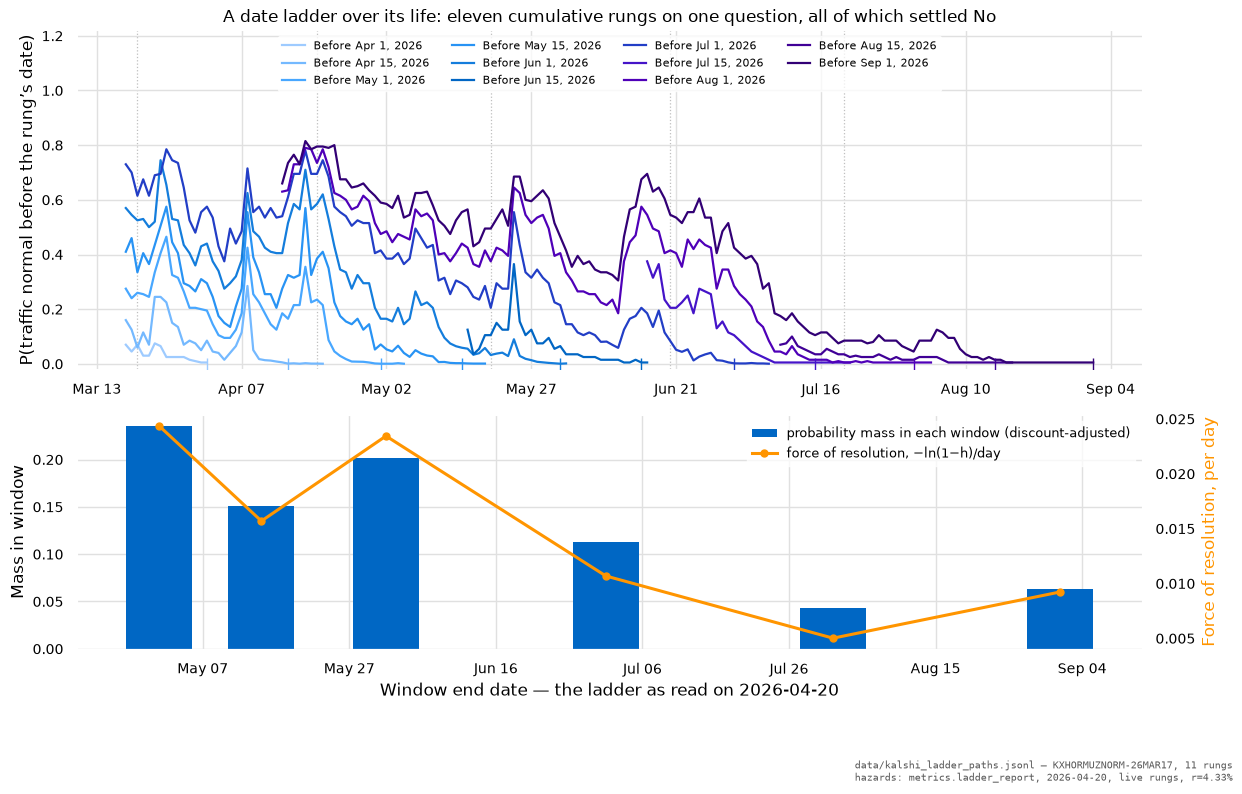

In [24]:
figure, (upper, lower) = pyplot.subplots(
    2, 1, figsize=(12.5, 8), height_ratios=(1.45, 1))

order = sorted(hormuz["rungs"], key=lambda r: kalshi.label_date(r["label"]) or 0)
# The house colour map rather than a stock one, so eleven rungs read as one ramp
# in the same palette as every other figure here.
colours = RUNG_RAMP(numpy.linspace(0.0, 1.0, len(order)))
for rung, colour in zip(order, colours):
    path = [c for c in (hormuz["paths"].get(rung["ticker"]) or []) if c.get("mid") is not None]
    if not path:
        continue
    days = [date2num(datetime.strptime(c["date"], "%Y-%m-%d")) for c in path]
    mids = [float(c["mid"]) for c in path]
    upper.plot(days, mids, color=colour, lw=1.6, label=rung["label"])
    deadline = kalshi.label_date(rung["label"])
    if deadline:
        upper.plot([date2num(datetime.fromtimestamp(deadline, UTC))], [0.0],
                   marker="|", markersize=9, color=colour, zorder=4)
for at in hormuz_ladders:
    upper.axvline(date2num(datetime.strptime(at, "%Y-%m-%d")), color="0.75", lw=0.9,
                  ls=":", zorder=0)
upper.set_ylabel("P(traffic normal before the rung’s date)")
upper.set_title("A date ladder over its life: eleven cumulative rungs on one question, "
                "all of which settled No", fontsize=12)
upper.set_ylim(-0.02, 1.22)
upper.legend(loc="upper center", ncols=4, fontsize=8)
upper.xaxis.set_major_formatter(DateFormatter("%b %d"))

pivot_hazard = [row for row in report["hazard"] if row["hazard"] is not None]
edges = [date2num(datetime.combine(row["horizon"], datetime.min.time()))
         for row in pivot_hazard]
lower.bar(edges, [row["mass"] for row in pivot_hazard], width=9, color=BLUE,
          zorder=2, label="probability mass in each window (discount-adjusted)")
twin = lower.twinx()
twin.plot(edges, [row["hazard_rate_per_day"] for row in pivot_hazard], color=ORANGE,
          lw=2.2, marker="o", markersize=5, zorder=3,
          label="force of resolution, −ln(1−h)/day")
twin.set_ylabel("Force of resolution, per day", color=ORANGE)
twin.grid(False)
lower.set_ylabel("Mass in window")
lower.set_xlabel(f"Window end date — the ladder as read on {PIVOT}")
lower.xaxis.set_major_formatter(DateFormatter("%b %d"))
handles, labels = lower.get_legend_handles_labels()
extra_h, extra_l = twin.get_legend_handles_labels()
lower.legend(handles + extra_h, labels + extra_l, loc="upper right", fontsize=9)

figure.tight_layout()
stamp("data/kalshi_ladder_paths.jsonl — KXHORMUZNORM-26MAR17, 11 rungs",
      f"hazards: metrics.ladder_report, {PIVOT}, live rungs, "
      f"r={report['rate']:.2%}",
      figure=figure)

### 4.3 How coherent are Kalshi's ladders, in general?

The harvest scored every open ladder it could find on a synchronous mid
snapshot. The answer is encouraging in aggregate and has one sharp exception,
which is the same exception section 3 found in the discount arithmetic.

In [25]:
live_coherence = read_rows("kalshi_live_ladder_coherence.jsonl")
closed_coherence = read_rows("kalshi_closed_ladder_coherence.jsonl")


def monotone_share(rows: Sequence[dict[str, Any]]) -> float:
    return (sum(1 for r in rows if r["monotone"]) / len(rows)) if rows else float("nan")


print(f"{len(live_coherence):,} open ladders scored on synchronous mids: "
      f"{monotone_share(live_coherence):.1%} monotone")
print(f"\n{'rungs':12} {'ladders':>8} {'monotone':>9}  {'median worst violation':>22}")
for lo, hi, label in ((2, 3, "2–3"), (4, 6, "4–6"), (7, 12, "7–12"), (13, 99, "13+")):
    group = [r for r in live_coherence if lo <= r["n_rungs"] <= hi]
    worst = statistics.median([r["max_violation"] for r in group]) if group else float("nan")
    print(f"{label:12} {len(group):8,} {monotone_share(group):9.1%}  {worst:22.3f}")

print(f"\n{'category':14} {'ladders':>8} {'monotone':>9}")
for category, _ in Counter(r["cat"] for r in live_coherence).most_common():
    group = [r for r in live_coherence if r["cat"] == category]
    print(f"{category:14} {len(group):8,} {monotone_share(group):9.1%}")

print(f"\nand {len(closed_coherence)} settled ladders, scored at a date inside their "
      f"life: {monotone_share(closed_coherence):.1%} monotone, median implied mass "
      f"{statistics.median([r['implied_mass'] for r in closed_coherence]):.2f}")
print("\nThe pattern is the opposite of the one provenance would predict: Elections, "
      "where resolution is a news event, carries the most coherent ladders; "
      "Economics, where resolution is arithmetic on a BLS print, carries the least. "
      "The next cell says why, and it is not about the settlement source.")

3,137 open ladders scored on synchronous mids: 91.4% monotone

rungs         ladders  monotone  median worst violation
2–3               111     98.2%                   0.000
4–6               957     94.7%                   0.000
7–12            1,903     92.5%                   0.000
13+               166     55.4%                   0.000

category        ladders  monotone
Elections         2,161     96.8%
Financials          471     79.8%
Economics           341     71.8%
Politics            164     93.9%

and 105 settled ladders, scored at a date inside their life: 65.7% monotone, median implied mass 0.61

The pattern is the opposite of the one provenance would predict: Elections, where resolution is a news event, carries the most coherent ladders; Economics, where resolution is arithmetic on a BLS print, carries the least. The next cell says why, and it is not about the settlement source.


### 4.4 What a decade-long ladder looks like

Kalshi lists inflation, unemployment and fed-funds ladders out to **December
2036**. Nothing on Polymarket trades past 48 months; the research doc found
four conflict markets beyond a year and all four were the same question. So the
long horizon this project cares about does, formally, exist here.

One live call on `KXUSCPIYEAR-37FEB01` — the CPI print for December 2036 — says
what it is worth.

In [26]:
LIVE.spend("GET /events/KXUSCPIYEAR-37FEB01", "with_nested_markets — the 2036 ladder")
distant_event = LIVE.reader.event("KXUSCPIYEAR-37FEB01", nested=True)
assert distant_event is not None
distant_rungs = sorted(
    (kalshi.normalise_market(m) for m in (distant_event.get("markets") or [])),
    key=lambda m: m["floor_strike"] or 0.0)
distant_ladder = survival_ladder(distant_rungs)

print(f"{distant_event['event_ticker']} — {distant_event['title']}")
print(f"{'rung':30} {'strike':>7} {'bid':>5} {'ask':>5} {'mid':>6} {'spread':>7} "
      f"{'bid sz':>8} {'ask sz':>8} {'volume':>9} {'OI':>7}")
for rung in distant_rungs:
    bid, ask = rung["yes_bid"], rung["yes_ask"]
    print(f"{rung['ticker']:30} {rung['floor_strike']:7.1f} "
          f"{bid if bid is not None else float('nan'):5.2f} "
          f"{ask if ask is not None else float('nan'):5.2f} "
          f"{(bid + ask) / 2.0 if bid is not None and ask is not None else float('nan'):6.3f} "
          f"{(ask - bid) if bid is not None and ask is not None else float('nan'):7.2f} "
          f"{rung['yes_bid_size'] or 0:8,.0f} {rung['yes_ask_size'] or 0:8,.0f} "
          f"{rung['volume']:9,.0f} {rung['open_interest']:7,.0f}")

violations = [(a, b) for a, b in zip(distant_ladder, distant_ladder[1:])
              if float(b["mid"]) > float(a["mid"]) + 1e-9]
tradeable = [(a, b) for a, b in zip(distant_ladder, distant_ladder[1:])
             if float(b["bid"]) > float(a["ask"]) + 1e-9]
spreads = [float(r["ask"]) - float(r["bid"]) for r in distant_ladder]
print(f"\n{len(distant_ladder)} two-sided rungs; "
      f"median spread {statistics.median(spreads):.2f} against the one-cent tick")
print(f"monotonicity violations on mids: {len(violations)}")
for a, b in violations:
    print(f"   S({a['x']:.1f}) = {a['mid']:.3f} but S({b['x']:.1f}) = {b['mid']:.3f} "
          f"— a rise of {float(b['mid']) - float(a['mid']):.3f}")
print(f"of which tradeable (ask on the higher strike below the bid on the lower): "
      f"{len(tradeable)}")
print(f"lifetime volume across the whole ladder: "
      f"{sum(r['volume'] for r in distant_rungs):,.0f} contracts; total open interest "
      f"{sum(r['open_interest'] for r in distant_rungs):,.0f}")

print("\nSo the ladder contradicts itself five ways on mids and offers nothing on "
      "either side of any of them, because every spread is wider than every "
      "violation. The incoherence is not an opportunity; it is the absence of a "
      "price. Read it the other way round and the lesson generalises: "
      "**coherence measured on the mid of a wide book measures nothing**, which is "
      "why the 13-rung group in 4.3 fails at 45% and why Economics is the venue's "
      "least coherent category — those are the decade-out macro ladders, not the "
      "monthly ones.")
print("\nAgainst that, the September ladder: "
      f"median spread {statistics.median([float(r['ask']) - float(r['bid']) for r in live_ladder]):.2f}, "
      f"{sum(r['volume'] for r in live_rungs):,.0f} contracts of volume, "
      f"{sum(r['open_interest'] for r in live_rungs):,.0f} of open interest. "
      "Same venue, same construction, same settlement source, ten years apart.")

KXUSCPIYEAR-37FEB01 — US headline CPI inflation in December 2036
rung                            strike   bid   ask    mid  spread   bid sz   ask sz    volume      OI
KXUSCPIYEAR-37FEB01-T0.0           0.0  0.78  0.99  0.885    0.21        2    1,000       382     240
KXUSCPIYEAR-37FEB01-T0.5           0.5  0.63  0.98  0.805    0.35        5      100       787     249
KXUSCPIYEAR-37FEB01-T1.0           1.0  0.36  0.99  0.675    0.63        7    1,000        14       7
KXUSCPIYEAR-37FEB01-T1.5           1.5  0.50  0.98  0.740    0.48        2        8        24       8
KXUSCPIYEAR-37FEB01-T2.0           2.0  0.01  0.61  0.310    0.60    1,000        3         9       6
KXUSCPIYEAR-37FEB01-T2.5           2.5  0.02  0.99  0.505    0.97        4    1,000         4       4
KXUSCPIYEAR-37FEB01-T3.0           3.0  0.30  0.67  0.485    0.37       10        2        17      13
KXUSCPIYEAR-37FEB01-T3.5           3.5  0.30  0.70  0.500    0.40       10       10         7       4
KXUSCPIYEAR-37FEB

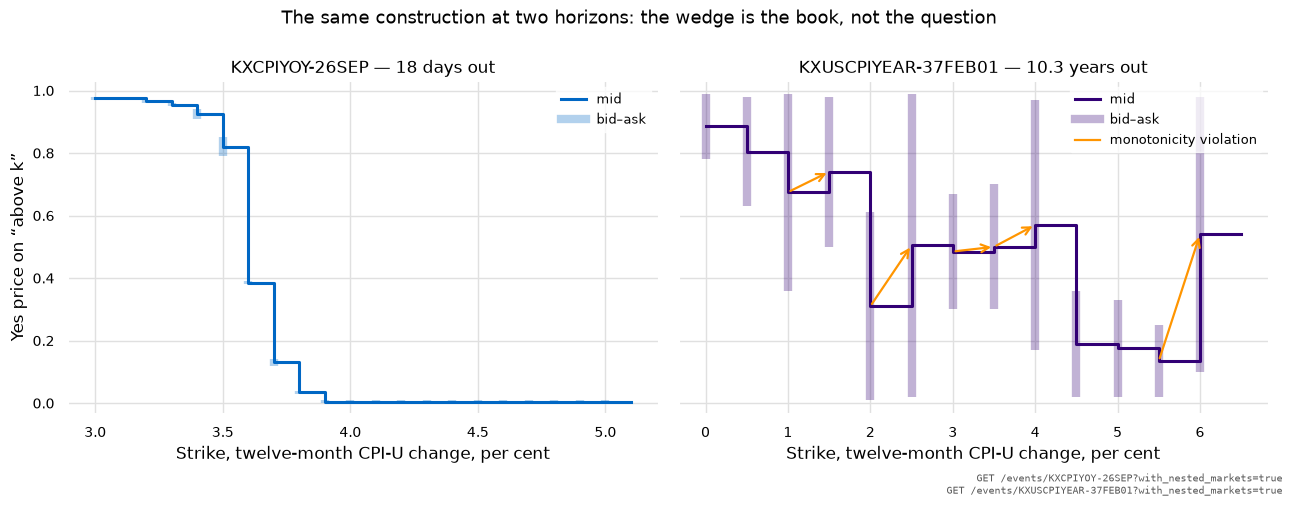

In [27]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5), sharey=True)

for axis, ladder, title, colour in (
        (left, live_ladder, "KXCPIYOY-26SEP — 18 days out", BLUE),
        (right, distant_ladder, "KXUSCPIYEAR-37FEB01 — 10.3 years out", PURPLE)):
    xs = [float(r["x"]) for r in ladder]
    axis.step([*xs, xs[-1] + (xs[-1] - xs[-2])],
              [*[float(r["mid"]) for r in ladder], float(ladder[-1]["mid"])],
              where="post", color=colour, lw=2.2, zorder=3, label="mid")
    for rung in ladder:
        axis.plot([float(rung["x"])] * 2, [float(rung["bid"]), float(rung["ask"])],
                  color=colour, lw=6, alpha=0.30, solid_capstyle="butt", zorder=2)
    axis.plot([], [], color=colour, lw=6, alpha=0.30, label="bid–ask")
    axis.set_title(title, fontsize=12)
    axis.set_xlabel("Strike, twelve-month CPI-U change, per cent")
    axis.set_ylim(-0.03, 1.03)
    axis.legend(loc="upper right", fontsize=9)
left.set_ylabel("Yes price on “above k”")
for a, b in violations:
    right.annotate("", xy=(float(b["x"]), float(b["mid"])),
                   xytext=(float(a["x"]), float(a["mid"])),
                   arrowprops={"arrowstyle": "->", "color": ORANGE, "lw": 1.6})
right.plot([], [], color=ORANGE, lw=1.6, label="monotonicity violation")
right.legend(loc="upper right", fontsize=9)

figure.suptitle("The same construction at two horizons: the wedge is the book, not the question",
                fontsize=13)
figure.tight_layout()
stamp("GET /events/KXCPIYOY-26SEP?with_nested_markets=true",
      "GET /events/KXUSCPIYEAR-37FEB01?with_nested_markets=true",
      figure=figure)

## 5. Price history, unauthenticated: how fine, how far back, and does it survive

Three questions, and Kalshi answers all three better than the read-only
assumption would suggest.

**How fine.** `period_interval` accepts exactly **1, 60 and 1440** minutes.
Everything else — 5, 15, 30, 240, 720, 10080 — is an HTTP 400. *(Established by
the harvest that built `data/`, recorded in `utils/kalshi.py`, and not re-tested
here: a deliberate 400 is a request spent on nothing.)* At most 5,000 candles
come back per call, so a full path is chunked.

**How far back.** The harvested corpus reaches **2021-09-25**, almost exactly
five years before this notebook was written, and the census finds 143 markets
that settled in 2021.

**Does a settled market keep it.** Yes, at every granularity, on the historical
route — which is the opposite of the conclusion the live route alone supports.
Section 1 showed the 404; the cell below shows what the historical route hands
back for the *same* market at one-minute resolution, three and a half years
after it settled.

Two calls, both on the historical tier.

In [28]:
def minute_window(ticker: str, start: datetime, end: datetime, label: str
                  ) -> list[dict[str, Any]]:
    """One-minute candles for a settled market, straight off the historical route."""
    LIVE.spend("GET /historical/markets/…/candlesticks", f"{label} (1-minute)")
    payload = LIVE.reader.get(f"/historical/markets/{ticker}/candlesticks",
                              allow_404=True, period_interval=1,
                              start_ts=int(start.timestamp()), end_ts=int(end.timestamp()))
    return [kalshi.normalise_candle(c) for c in (payload or {}).get("candlesticks") or []]


# A market settled in January 2023, read at one-minute granularity today.
old_minutes = minute_window(
    "CPIYOY-22DEC-T6.5",
    datetime(2023, 1, 12, 0, tzinfo=UTC), datetime(2023, 1, 12, 23, tzinfo=UTC),
    "CPIYOY-22DEC-T6.5 on its release day")
print(f"CPIYOY-22DEC-T6.5, settled {'2023-01':>7}: "
      f"{len(old_minutes)} one-minute candles on 2023-01-12, "
      f"{sum(1 for c in old_minutes if c['traded'])} of them with a trade")
for candle in old_minutes[:4]:
    when = datetime.fromtimestamp(candle["ts"], UTC)
    print(f"   {when:%H:%M} bid {candle['yes_bid']:.2f} ask {candle['yes_ask']:.2f} "
          f"mid {candle['mid']:.3f} volume {candle['volume']:8,.0f} "
          f"traded {candle['traded']}")
print("— so the minute grain survives, but the candles are SPARSE: only minutes in "
      "which something happened come back, not 1,440 rows a day. A gap in the "
      "series is silence, not missing data, and any resampling has to forward-fill "
      "rather than interpolate.")

# The release-morning window on a 2026 rung, which is where the pre-close trap lives.
release_minutes = {
    ticker: minute_window(ticker, datetime(2026, 6, 10, 10, tzinfo=UTC),
                          datetime(2026, 6, 10, 14, tzinfo=UTC), ticker)
    for ticker in ("KXCPIYOY-26MAY-T4.2",)}
for ticker, candles in release_minutes.items():
    traded = [c for c in candles if c["traded"]]
    print(f"\n{ticker} on release morning: {len(candles)} minute candles, "
          f"{len(traded)} traded, "
          f"{datetime.fromtimestamp(candles[0]['ts'], UTC):%H:%M}–"
          f"{datetime.fromtimestamp(candles[-1]['ts'], UTC):%H:%M} UTC")
    for candle in candles[-3:]:
        when = datetime.fromtimestamp(candle["ts"], UTC)
        print(f"   {when:%H:%M} bid {candle['yes_bid']:.2f} ask {candle['yes_ask']:.2f} "
              f"mid {candle['mid']:.3f} volume {candle['volume']:8,.0f}")

print("\nAnd there is the trap. The last minute candle reports bid 0.00, ask 1.00 "
      "and therefore a MID OF 0.50 — that is the empty book after the close, not a "
      "forecast of a coin flip. Anything that reads a market's terminal quote off "
      "its final one-minute candle will read 0.5 on every settled market on the "
      "venue. The daily candles do not show it, because the day aggregates a real "
      "session around it, which is the reason the calibration corpus is built at "
      "1440 and not at 1.")

CPIYOY-22DEC-T6.5, settled 2023-01: 7 one-minute candles on 2023-01-12, 3 of them with a trade
   04:13 bid 0.13 ask 0.16 mid 0.145 volume       75 traded True
   04:16 bid 0.13 ask 0.16 mid 0.145 volume      625 traded True
   13:01 bid 0.11 ask 0.15 mid 0.130 volume      803 traded True
   13:03 bid 0.11 ask 0.16 mid 0.135 volume        0 traded False
— so the minute grain survives, but the candles are SPARSE: only minutes in which something happened come back, not 1,440 rows a day. A gap in the series is silence, not missing data, and any resampling has to forward-fill rather than interpolate.



KXCPIYOY-26MAY-T4.2 on release morning: 113 minute candles, 64 traded, 10:04–12:30 UTC
   12:28 bid 0.41 ask 0.53 mid 0.470 volume       69
   12:29 bid 0.41 ask 0.65 mid 0.530 volume       76
   12:30 bid 0.00 ask 1.00 mid 0.500 volume        0

And there is the trap. The last minute candle reports bid 0.00, ask 1.00 and therefore a MID OF 0.50 — that is the empty book after the close, not a forecast of a coin flip. Anything that reads a market's terminal quote off its final one-minute candle will read 0.5 on every settled market on the venue. The daily candles do not show it, because the day aggregates a real session around it, which is the reason the calibration corpus is built at 1440 and not at 1.


In [29]:
year_counts: Counter[str] = Counter()
earliest, latest = None, None
oi_recovered = 0
for line in (DATA / "kalshi_candles.jsonl").open():
    row = json.loads(line)
    candles = row["candles"]
    if not candles:
        continue
    for candle in candles:
        year_counts[candle["date"][:4]] += 1
    first, last = candles[0]["date"], candles[-1]["date"]
    earliest = first if earliest is None or first < earliest else earliest
    latest = last if latest is None or last > latest else latest
    if max((c["open_interest"] for c in candles), default=0.0) > 0:
        oi_recovered += 1

print(f"stored daily paths: {earliest} .. {latest}")
print(f"{'year':6} {'candles':>10}")
for year in sorted(year_counts):
    print(f"{year:6} {year_counts[year]:10,}")

zeroed = sum(1 for r in quality_rows if not r.get("open_interest"))
peaks = sorted(r["peak_open_interest"] for r in quality_rows
               if r.get("peak_open_interest"))
print(f"\nopen interest on the settled market ROW reads zero on "
      f"{zeroed:,} of {len(quality_rows):,} markets — it is a live position count, "
      f"not a record")
print(f"recovered from the candles instead on {oi_recovered:,} paths; "
      f"median peak {statistics.median(peaks):,.0f} contracts, "
      f"90th percentile {quantile(peaks, 0.9):,.0f}")
biggest = max(quality_rows, key=lambda r: r.get("peak_open_interest") or 0.0)
print(f"largest: {biggest['ticker']} — row open_interest "
      f"{biggest['open_interest']:,.0f}, candle peak "
      f"{biggest['peak_open_interest']:,.0f}, lifetime volume {biggest['volume']:,.0f}")
print("A quality screen that reads OI off the market row scores every settled "
      "market on the venue as having attracted no interest whatever.")

stored daily paths: 2021-09-25 .. 2026-09-25
year      candles
2021           88
2022       18,564
2023       37,684
2024       69,804
2025      415,322
2026      201,603

open interest on the settled market ROW reads zero on 3,732 of 4,369 markets — it is a live position count, not a record
recovered from the candles instead on 4,389 paths; median peak 63,983 contracts, 90th percentile 586,581
largest: PRES-2024-KH — row open_interest 0, candle peak 84,647,638, lifetime volume 273,312,857
A quality screen that reads OI off the market row scores every settled market on the venue as having attracted no interest whatever.


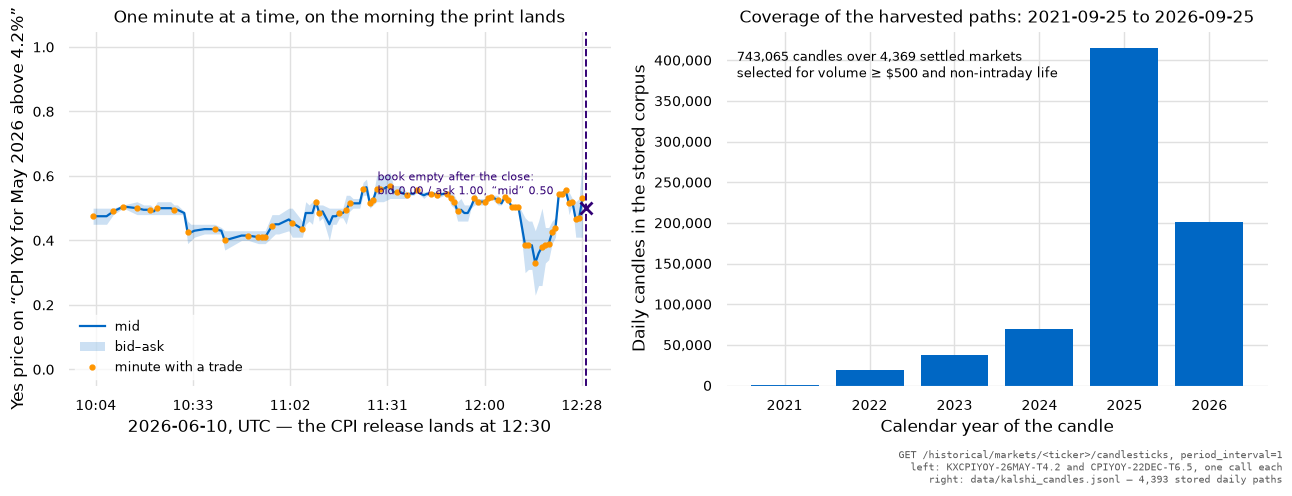

In [30]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5))

ticker, candles = next(iter(release_minutes.items()))
quoted = [c for c in candles if c["mid"] is not None]
# Drop the post-close candle from the price series and mark it instead: plotting
# it would draw a 30-cent move to 0.5 that never traded.
session = quoted[:-1] if quoted and quoted[-1]["yes_bid"] == 0.0 and quoted[-1]["yes_ask"] == 1.0 else quoted
minutes = [date2num(datetime.fromtimestamp(c["ts"], UTC)) for c in session]
left.plot(minutes, [c["mid"] for c in session], color=BLUE, lw=1.6, label="mid")
left.fill_between(minutes, [c["yes_bid"] for c in session], [c["yes_ask"] for c in session],
                  color=BLUE, alpha=0.20, lw=0, label="bid–ask")
traded_at = [date2num(datetime.fromtimestamp(c["ts"], UTC)) for c in session if c["traded"]]
left.plot(traded_at, [c["mid"] for c in session if c["traded"]], linestyle="none",
          marker="o", markersize=3.5, color=ORANGE, label="minute with a trade")
if quoted and quoted[-1] is not session[-1]:
    closed_at = date2num(datetime.fromtimestamp(quoted[-1]["ts"], UTC))
    left.axvline(closed_at, color=PURPLE, lw=1.4, ls="--")
    left.plot([closed_at], [0.5], marker="x", markersize=9, mew=2.0, color=PURPLE)
    left.annotate("book empty after the close:\nbid 0.00 / ask 1.00, “mid” 0.50",
                  (closed_at, 0.5), textcoords="offset points", xytext=(-150, 10),
                  fontsize=8, color=PURPLE)
left.xaxis.set_major_formatter(DateFormatter("%H:%M"))
left.set_xlabel("2026-06-10, UTC — the CPI release lands at 12:30")
left.set_ylabel("Yes price on “CPI YoY for May 2026 above 4.2%”")
left.set_title("One minute at a time, on the morning the print lands", fontsize=12)
left.set_ylim(-0.05, 1.05)
left.legend(loc="lower left", fontsize=9)

years = sorted(year_counts)
right.bar(range(len(years)), [year_counts[y] for y in years], color=BLUE, zorder=2)
right.set_xticks(range(len(years)), years)
right.set_xlabel("Calendar year of the candle")
right.set_ylabel("Daily candles in the stored corpus")
right.set_title(f"Coverage of the harvested paths: {earliest} to {latest}", fontsize=12)
right.yaxis.set_major_formatter(lambda v, _pos: f"{v:,.0f}")
right.text(0.02, 0.95, f"{sum(year_counts.values()):,} candles over "
                       f"{len(quality_rows):,} settled markets\n"
                       "selected for volume ≥ $500 and non-intraday life",
           transform=right.transAxes, fontsize=9, va="top")

figure.tight_layout()
stamp("GET /historical/markets/<ticker>/candlesticks, period_interval=1",
      f"left: {ticker} and CPIYOY-22DEC-T6.5, one call each",
      "right: data/kalshi_candles.jsonl — 4,393 stored daily paths",
      figure=figure)

## 6. Volume is not interest — and on this venue it is not even money

The Polymarket finding is stark: one event reported **$1.29bn of volume against
$10.1m of open interest**, 128× turnover, with 87% of a sibling event's volume
sitting in outcomes priced under two cents. Kalshi's version of the problem is
smaller and differently shaped, and both parts of that are worth saying.

**Smaller, because turnover here is about 2×, not 128×.** Kalshi's volume is
recoverable against a real interest measure — the candle-derived peak open
interest of section 5 — and the ratio is sane across the whole corpus.

**Differently shaped, because Kalshi's `volume` is a contract count, not a
dollar figure.** A contract pays $1, so a count looks like a dollar amount and
is quoted as one; but the money that changed hands is the count times the price
it traded at, and on a ladder most rungs trade at a few cents. The candle path
carries a per-period volume-weighted mean price, so the money **is** recoverable
— and it is a third of the headline.

In [31]:
turnover = sorted((r["total_candle_volume"] / r["peak_open_interest"])
                  for r in quality_rows
                  if r.get("peak_open_interest") and r.get("total_candle_volume"))
print(f"volume ÷ peak open interest over {len(turnover):,} settled markets: "
      f"median {statistics.median(turnover):.2f}×, "
      f"p90 {quantile(turnover, 0.9):.2f}×, max {turnover[-1]:,.0f}×")
print(f"the Polymarket reference event ran at 128× on a two-year horizon; "
      f"{sum(1 for t in turnover if t > 128):,} of {len(turnover):,} Kalshi markets "
      f"({sum(1 for t in turnover if t > 128) / len(turnover):.2%}) reach that")

print(f"\ncontracts against money, on the April 2025 inflation ladder:")
print(f"{'rung':26} {'strike':>7} {'contracts':>12} {'dollars':>12} {'avg price':>10}")
count_total = money_total = 0.0
tail_count = tail_money = 0.0
for ticker in sorted(april_paths):
    candles = april_paths[ticker]
    count = sum(c["volume"] for c in candles)
    money = sum((c["mean"] if c["mean"] is not None else (c["close"] or 0.0)) * c["volume"]
                for c in candles)
    strike = next(m["floor_strike"] for m in april_markets if m["ticker"] == ticker)
    print(f"{ticker:26} {strike:7.1f} {count:12,.0f} {money:12,.0f} "
          f"{money / count if count else 0:10.3f}")
    count_total += count
    money_total += money
    if strike is not None and strike > april_truth["bracketed"] + 0.3:
        tail_count += count
        tail_money += money
print(f"{'TOTAL':26} {'':7} {count_total:12,.0f} {money_total:12,.0f} "
      f"{money_total / count_total:10.3f}")
print(f"\nheadline volume {count_total:,.0f} 'dollars'; money actually traded "
      f"${money_total:,.0f}, i.e. {money_total / count_total:.1%} of it")
print(f"rungs more than 0.3pp above the realised print: {tail_count / count_total:.1%} "
      f"of the contract count and {tail_money / money_total:.1%} of the money")

heavy = max(quality_rows, key=lambda r: r.get("volume") or 0.0)
print(f"\nand the single largest market in the corpus, for scale: {heavy['ticker']} — "
      f"volume {heavy['volume']:,.0f} contracts, row open interest "
      f"{heavy['open_interest']:,.0f}, candle peak "
      f"{heavy['peak_open_interest']:,.0f}, traded on "
      f"{heavy['traded_frac']:.0%} of its {heavy['n_periods']} days")
print("\nOne thing Kalshi can do here that Polymarket structurally cannot: its "
      "public trade tape carries `taker_side`, `taker_book_side` and "
      "`is_block_trade` per print, so signed order flow and negotiated-block share "
      "are computable from public data. `metrics.NOT_COMPUTABLE` lists "
      "`order_flow_toxicity` as impossible because public tapes give no aggressor "
      "side — that entry is right about the other three venues and **wrong about "
      "this one**. No tape is pulled here (it is a call per market and adds "
      "nothing to the argument), but the capability belongs in the record.")

volume ÷ peak open interest over 4,362 settled markets: median 1.95×, p90 3.78×, max 1,166×
the Polymarket reference event ran at 128× on a two-year horizon; 8 of 4,362 Kalshi markets (0.18%) reach that

contracts against money, on the April 2025 inflation ladder:
rung                        strike    contracts      dollars  avg price
KXCPIYOY-25APR-T2.2            2.2    2,025,012    1,690,874      0.835
KXCPIYOY-25APR-T2.3            2.3    1,659,081      994,015      0.599
KXCPIYOY-25APR-T2.4            2.4    2,188,024      618,531      0.283
KXCPIYOY-25APR-T2.5            2.5    2,257,174      281,615      0.125
KXCPIYOY-25APR-T2.6            2.6    1,686,915      119,731      0.071
KXCPIYOY-25APR-T2.7            2.7      405,431       27,224      0.067
KXCPIYOY-25APR-T2.8            2.8      273,957       15,304      0.056
KXCPIYOY-25APR-T2.9            2.9      234,854       12,458      0.053
KXCPIYOY-25APR-T3.0            3.0      222,540        8,997      0.040
KXCPIYOY-25APR-

## 7. A worked quality read

`metrics.py` is the catalogue of everything public data can say about market
quality, written to be complete rather than convenient: where a measure a
trader would want cannot be computed, it is named in `NOT_COMPUTABLE` with the
reason instead of being quietly dropped. `kalshi.QUALITY_METRICS` is the same
exercise narrowed to this venue, with a trust verdict per metric.

The composite deliberately does not exist. There is no single score, because
the measurements do not commensurate — a market can have a one-cent spread and
two hundred dollars of depth, as section 3 showed — and collapsing them is
exactly how `liquidityNum` came to rank a zero-bid contract as its event's most
liquid. Filter on the gates individually.

Three markets, chosen from the corpus by the metric that discriminates best.

In [32]:
print(f"{'metric':26} {'trust':<11} {'source':<44} note")
for name, source, trust, note in kalshi.QUALITY_METRICS:
    print(f"{name:26} {trust:<11} {source:<44} {note[:58]}")

metric                     trust       source                                       note
volume                     no          market.volume_fp                             turnover, not interest; a rung can churn without anyone ho
open_interest              live only   market.open_interest_fp                      the honest interest measure WHILE OPEN; zeroed the moment 
liquidity                  never       market.liquidity_dollars                     reads 0.0000 on a 17-level book with $46k OI; not a depth 
quoted_spread              yes         market.yes_ask - market.yes_bid              absolute spread; compare relative to mid, not in cents
size_at_touch              yes         market.yes_bid_size_fp / yes_ask_size_fp     top-of-book size per side, free on the row; 571 vs 5,618 i
settlement_source          yes         series.settlement_sources[].name/url         the named authority; present on 100% of target series
contract_terms             yes         series.contract_terms_u

In [33]:
scored = [r for r in quality_rows
          if r.get("traded_frac") is not None and (r.get("volume") or 0) > 0]
scored.sort(key=lambda r: r["traded_frac"])
picks = {"the thinnest decile": scored[len(scored) // 10],
         "the median market": scored[len(scored) // 2],
         "the busiest market": max(scored, key=lambda r: r.get("peak_open_interest") or 0.0)}

print(f"{'':22} " + " ".join(f"{k:>22}" for k in picks))
print(f"{'ticker':22} " + " ".join(f"{r['ticker']:>22}" for r in picks.values()))
print(f"{'category':22} " + " ".join(f"{str(r.get('category')):>22}" for r in picks.values()))
for field, fmt, verdict in (
        ("life_days", "{:22,.0f}", ""),
        ("n_periods", "{:22,.0f}", "days with any candle"),
        ("traded_frac", "{:22.1%}", "share of life that traded — the best single gate"),
        ("two_sided_frac", "{:22.1%}", "share of days with a genuine two-sided quote"),
        ("median_rel_spread", "{:22.1%}", "spread over mid, whole life"),
        ("frac_periods_unchanged", "{:22.1%}", "days the price did not move at all"),
        ("n_distinct_prices", "{:22,.0f}", "a step function is not a probability path"),
        ("median_abs_move", "{:22.4f}", "typical daily move"),
        ("volume", "{:22,.0f}", "contracts, lifetime"),
        ("peak_open_interest", "{:22,.0f}", "contracts, recovered from candles"),
        ("open_interest", "{:22,.0f}", "the row's own value — zero on 85% of settled markets")):
    cells = []
    for row in picks.values():
        value = row.get(field)
        cells.append(fmt.format(value) if value is not None else f"{'—':>22}")
    print(f"{field:22} " + " ".join(cells) + (f"   {verdict}" if verdict else ""))

print("\nwhat good and bad look like, on this venue, from the corpus rather than "
      "from taste:")
for field, good, bad in (("traded_frac", "> 0.6", "< 0.1"),
                         ("median_rel_spread", "< 0.05", "> 0.5"),
                         ("frac_periods_unchanged", "< 0.3", "> 0.8"),
                         ("peak_open_interest", "> 50,000 contracts", "< 1,000")):
    values = sorted(r[field] for r in quality_rows if r.get(field) is not None)
    print(f"  {field:24} median {statistics.median(values):10.4f}   "
          f"p10 {quantile(values, 0.10):10.4f}   p90 {quantile(values, 0.90):10.4f}   "
          f"good {good:20} bad {bad}")

print(f"\nand the measures that are unavailable here, named rather than omitted:")
for name, reason in metrics.NOT_COMPUTABLE.items():
    if name.startswith("predictit"):
        continue
    print(f"  {name:26} {reason.split('.')[0]}.")
print(f"\n  {'holder_concentration':26} not served by Kalshi at all — "
      f"metrics.VENUE_COVERAGE marks it 'no' for this venue, so wallet or account "
      f"concentration is simply unknowable here, and the 2024 'French whale' "
      f"question cannot be asked of a Kalshi market.")
print(f"  {'dispute_history':26} not served, and arguably not applicable: "
      f"CFTC-regulated settlement against a named statistic is not a dispute "
      f"process in Polymarket's sense. That is a strength on resolution quality "
      f"and a gap in the data — there is no `was_disputed` flag to screen on.")

kalshi_coverage = {metric: table["kalshi"] for metric, table in metrics.VENUE_COVERAGE.items()}
print(f"\n{'metric family':44} {'kalshi':<10} note")
for metric, (status, note) in kalshi_coverage.items():
    print(f"{metric:44} {status:<10} {note[:56]}")

                          the thinnest decile      the median market     the busiest market
ticker                      KXFED-26JUL-T4.75 KXSUPPORTPARTYMUSKD-25           PRES-2024-KH
category                            Economics               Politics               Politics
life_days                                 357                    210                    108
n_periods                                 269                    210                    108   days with any candle
traded_frac                              6.7%                  54.3%                 100.0%   share of life that traded — the best single gate
two_sided_frac                           4.5%                  90.5%                  61.1%   share of days with a genuine two-sided quote
median_rel_spread                       66.7%                  58.8%                  40.0%   spread over mid, whole life
frac_periods_unchanged                  82.3%                  15.0%                  27.1%   days the price did 

## 8. What it cannot do, and why it is not a choice

The one thing Polymarket offers that nothing else does is a price on armed
conflict. Kalshi has none, and the reason is not product strategy.

**17 CFR 40.11(a)(1)** bars a registered entity from listing or clearing a
contract "based upon an excluded commodity, as defined in Section 1a(19)(iv) of
the Act, that involves, relates to, or references terrorism, assassination,
war, gaming, or an activity that is unlawful under any State or Federal law" —
verified verbatim from govinfo's official XML by the research doc's verification
pass. The CFTC's **pending** proposed rule *Prediction Markets; Public Interest
Determinations* (91 FR 35806, 2026-06-12, **not final**) works the exclusion out
on this project's own example: a contract on "whether Iran initiates armed
conflict in the Strait of Hormuz… would involve war or terrorism", whereas one
on "a specified volume of crude oil transit[ing] the Strait… does not."

So the absence is a regulatory fact rather than a gap in coverage, and it will
not be filled by Kalshi listing more markets. But an absence asserted is worth
nothing, so the next two cells establish it by search — first over all 14,392
series titles, then over 105,205 market rule texts, which is the stronger test
because the rule text is where the actual contract lives.

In [34]:
CONFLICT_TERMS = ("war", "invade", "invasion", "ceasefire", "armistice", "conflict",
                  "coup", "assassinat", "terror", "strike", "nuclear", "missile",
                  "troops", "military", "insurgen", "annex")
patterns = {term: re.compile(r"\b" + term, re.I) for term in CONFLICT_TERMS}

series_hits: list[tuple[dict[str, Any], list[str]]] = []
for s in series_rows:
    blob = " ".join([s["ticker"], s["title"], s["category"], " ".join(s.get("tags") or [])])
    matched = [term for term, pattern in patterns.items() if pattern.search(blob)]
    if matched:
        series_hits.append((s, matched))

print(f"{len(series_hits)} of {len(series_rows):,} series match a conflict term "
      f"anywhere in ticker, title, category or tags")
print(f"which terms: " + ", ".join(f"{t} {n}" for t, n in
      Counter(t for _, ms in series_hits for t in ms).most_common()))
# Sports and entertainment hits are obvious noise (Counter-Strike, Coupe de
# France, Love Island couples). The interesting sample is the one a careless
# filter would keep: matches inside the categories this project actually reads.
political_hits = [(s, m) for s, m in series_hits
                  if s["category"] in ("Politics", "Economics", "World", "Elections",
                                       "Financials")]
print(f"\nof those, {len(political_hits)} sit in Politics, Economics, World, "
      f"Elections or Financials — the categories a conflict screen would keep. "
      f"What they actually are:")
for s, matched in political_hits[:22]:
    print(f"  {s['ticker']:26} {s['category'][:11]:11} {str(matched):18} {s['title'][:46]}")
print(f"  … and {max(0, len(political_hits) - 22)} more of the same kind")
print("\nEvery one is a false positive, and the ways they are false are worth "
      "noticing: 'Warsh' and 'Warren' and 'Warner' contain 'war'; a 'travel "
      "WARNing' does too; 'strike' is a labour dispute or a bill being struck "
      "down; 'nuclear' is a reactor licence or a fusion milestone; 'military' is "
      "an appropriations bill. The word-level search is almost entirely noise, "
      "which is itself the finding — there is nothing for it to hit. It also "
      "makes the research doc's point about registries: a term list applied to a "
      "vendor's vocabulary produces a count, and the count is wrong.")

126 of 14,392 series match a conflict term anywhere in ticker, title, category or tags
which terms: war 66, strike 37, coup 9, nuclear 9, military 4, terror 1

of those, 65 sit in Politics, Economics, World, Elections or Financials — the categories a conflict screen would keep. What they actually are:
  POWELLLEAVE                Politics    ['war']            Powell leaving
  KXARGSTRIKE                World       ['strike']         General strike in Argentina
  IVYFUNDING                 Politics    ['war']            Ivy League funding
  KXGREENLANDMILITARYBILL    Politics    ['military']       Will a bill pass to Congressional approval for
  TRAVELWARN                 World       ['war']            "Do Not Travel" warning issued for Beijing
  HFHOUSING                  Politics    ['war']            Bill taxing/banning hedge funds owning single-
  KXEOCOUNTDAY1C             Politics    ['strike']         Day 1 executive orders EVEN MORE STRIKES
  DEBATEHAPPEN               Politics

In [35]:
EVENT_PATTERNS = {
    "armed conflict": re.compile(
        r"\b(declares? war|goes to war|at war with|armed conflict|invades?|"
        r"invasion of|military invasion)\b", re.I),
    "ceasefire or armistice": re.compile(r"\bceasefire|cease-fire|armistice\b", re.I),
    "assassination": re.compile(r"\bassassinat", re.I),
    "terrorism": re.compile(r"\bterrorist attack|act of terror|terrorism\b", re.I),
    "nuclear use": re.compile(r"\bnuclear (weapon|detonat|strike|test)", re.I),
    "coup": re.compile(r"\bcoup d|coup attempt|military coup\b", re.I),
}
rule_hits: dict[str, list[tuple[str, str]]] = {k: [] for k in EVENT_PATTERNS}
searched = 0
for line in (DATA / "kalshi_markets.jsonl").open():
    row = json.loads(line)
    searched += 1
    blob = f"{row.get('title') or ''} {row.get('rules_primary') or ''}"
    for name, pattern in EVENT_PATTERNS.items():
        if pattern.search(blob):
            rule_hits[name].append((row["ticker"], (row.get("title") or "")[:64]))

print(f"{searched:,} market rows searched on title AND rules_primary — the contract "
      f"text itself, not the label\n")
print(f"{'event class':24} {'markets':>8}  the hits, in full")
for name, hits in rule_hits.items():
    print(f"{name:24} {len(hits):8}")
    for ticker, title in hits[:4]:
        print(f"{'':24} {'':8}  {ticker:28} {title}")
print("\nZero on armed conflict, zero on terrorism, zero on nuclear use, zero on "
      "coups, across a hundred thousand contracts. The single 'ceasefire' hit is a "
      "market on what a vice-president would SAY on a television programme; the "
      "single 'assassination' hit is a market on releasing the JFK files.")

105,205 market rows searched on title AND rules_primary — the contract text itself, not the label

event class               markets  the hits, in full
armed conflict                  0
ceasefire or armistice          1
                                   KXVANCEINGRAHAM-25MAR14-CEASEFIRE What will J.D. Vance say on Ingraham Angle?
assassination                   1
                                   KXJFKFILES-26                Will Trump releases more JFK files?
terrorism                       0
nuclear use                     0
coup                            0

Zero on armed conflict, zero on terrorism, zero on nuclear use, zero on coups, across a hundred thousand contracts. The single 'ceasefire' hit is a market on what a vice-president would SAY on a television programme; the single 'assassination' hit is a market on releasing the JFK files.


### Where the line actually falls

The proposed rule's own distinction — the act is barred, the measurable
consequence is not — is visible in the catalogue as a family of twelve Strait of
Hormuz series that price shipping statistics, and it produced one of the most
striking settled markets on the venue.

In [36]:
hormuz_family = [s for s in series_rows
                 if re.search(r"hormuz|portwatch", s["ticker"] + " " + s["title"], re.I)]
print(f"{len(hormuz_family)} Strait of Hormuz series, and what each one references:")
for s in sorted(hormuz_family, key=lambda s: s["ticker"]):
    print(f"  {s['ticker']:22} {s['title'][:56]:56} {str(s['source_names'])[:36]}")

closure = [m for m in (json.loads(line) for line in (DATA / "kalshi_markets.jsonl").open())
           if m["series_ticker"] == "KXCLOSEHORMUZ"]
print(f"\nand the one that sits closest to the line, settled:")
for m in sorted(closure, key=lambda m: m["close_time"]):
    print(f"  {m['ticker']:32} {m['title']}")
    print(f"  {'':32} rule: {m['rules_primary']}")
    print(f"  {'':32} result {m['result']}, expiration_value {m['expiration_value']!r}, "
          f"volume {m['volume']:,.0f}, closed {m['close_time'][:10]}")

print("\nSo: *did Iran close the Strait* is listable in the United States, and it "
      "resolved Yes in March 2026 on 7.3m contracts across three rungs. *Will "
      "Iran initiate armed conflict* is not listable, and there is no market on it "
      "here at any price. The regulation does not draw the line where a forecaster "
      "would; it draws it between an act of war and an observable consequence of "
      "one, and a reader looking for conflict exposure on this venue gets the "
      "consequence or nothing.")

12 Strait of Hormuz series, and what each one references:
  KXCLOSEHORMUZ          Strait of Hormuz                                         ['ABC', 'Al Jazeera', 'BBC', 'Bloomb
  KXHORMUZAVG            How high will average weekly Hormuz transits get in 2026 ['the Statistical Review of World En
  KXHORMUZMAX            Maximum traffic through the Strait of Hormuz?            ['IMF PortWatch']
  KXHORMUZNORM           When will traffic at the Strait of Hormuz return to norm ['the Statistical Review of World En
  KXHORMUZPEAK           Peak traffic through the Strait of Hormuz?               ['IMF PortWatch']
  KXHORMUZRENAME         Will Trump rename the Strait of Hormuz?                  ['the White House', 'Federal Registe
  KXHORMUZRETURN         When will the Strait of Hormuz return to normal traffic? ['the Statistical Review of World En
  KXHORMUZTRAFFIC        Ship volume through the Strait of Hormuz?                ['the Statistical Review of World En
  KXHORMUZTRAFFICW       Tra


and the one that sits closest to the line, settled:
  KXCLOSEHORMUZ-25JUL              Will Iran close Strait of Hormuz before Jul 2025?
                                   rule: If Iran closes Strait of Hormuz before Jul 1, 2025, then the market resolves to Yes.
                                   result no, expiration_value 'No', volume 3,331, closed 2025-07-01
  KXCLOSEHORMUZ-27JAN-26MAY        Will Iran close Strait of Hormuz before May 2026?
                                   rule: If Iran has effectively closed Strait of Hormuz to cargo and tanker ships after Issuance and before May 1, 2026, then the market resolves to Yes.
                                   result yes, expiration_value 'Yes', volume 3,602,654, closed 2026-03-10
  KXCLOSEHORMUZ-27JAN-26AUG        Will Iran close Strait of Hormuz before Aug 2026?
                                   rule: If Iran has effectively closed Strait of Hormuz to cargo and tanker ships after Issuance and before Aug 1, 2026, then the market r

## 9. Longshot bias and calibration, measured on Kalshi's own closed corpus

The published numbers are about other venues or other samples: −19.3¢ per
dollar below ten cents on Polymarket; a calibration slope rising to 1.32 at one
month and beyond in the cross-venue literature; 78% of Kalshi's 2024 political
markets beating chance in the one peer-reviewed four-venue study. None of those
is a measurement of *this* corpus, so the corpus gets measured.

**Three things about the sample, before any number.** All three are in
`corpus.FORCED` and all three limit what follows.

1. **It is liquidity-stratified, not a population.** The harvest stored paths for
   markets with volume ≥ $500 and a life longer than a day — 4,393 of 100,233
   settled markets. Anything below that floor is absent, so these figures describe
   *tradeable* Kalshi, which is the right population for this purpose and the
   wrong one for "how good is the average Kalshi market".
2. **The price is a mid, not a print.** Kalshi's daily candle has a null close on
   the 45% of days with no trade but a live quote on all of them, so the panel
   reads the mid and falls back to the close. `corpus.kalshi_price_basis_sensitivity`
   measures what that choice costs; `calibration.ipynb` reports it.
3. **`result == "scalar"` is excluded.** Those markets paid out at a price rather
   than against the world, so their outcome is their own forecast.

And one reduction that makes the *n* honest: consecutive days of one market are
approximately the same forecast, so scoring market-days overstates the evidence
by the length of the market. `corpus.market_bucket_rows` keeps one observation
per market per horizon bucket, choosing the row nearest the bucket's geometric
centre.

In [37]:
started = time.monotonic()
print("loading the Kalshi half of the panel from disk (128 MB of candles) …")
panel = corpus.load_panel(venues=("kalshi",), progress=lambda m: print(f"  {m}"))
print(f"  done in {time.monotonic() - started:.0f}s")
described = panel.describe()
print(f"\n{described['markets']:,} settled markets, {described['observations']:,} "
      f"market-days, longest horizon {described['max_horizon_days']:.0f} days")

rows = corpus.market_bucket_rows(panel)
price, outcome = rows["price"], rows["outcome"]
print(f"reduced to {len(price):,} market-horizon-bucket rows — the honest n")

overall = corpus.brier(price, outcome) | corpus.calibration_slope(price, outcome)
print(f"\nover the whole corpus:")
print(f"  Brier {overall['brier']:.4f} against a climatological "
      f"{overall['climatological']:.4f} on the sample's own "
      f"{overall['base_rate']:.1%} base rate")
print(f"  Brier skill {overall['skill']:.3f}")
print(f"  calibration slope, linear {overall['slope_linear']:.3f} "
      f"(1.0 is calibrated; below 1 overconfident, above 1 underconfident)")
print(f"  calibration slope, logit  {overall['slope_logit']:.3f} "
      f"— reported for comparability with the published figures, which are "
      f"logit-based, and NOT comparable to the linear one")

print(f"\n{'horizon':10} {'rows':>6} {'markets':>8} {'base':>7} {'brier':>8} "
      f"{'skill':>7} {'slope':>7}")
horizon_stats: list[dict[str, Any]] = []
for index, label in enumerate(corpus.HORIZON_LABELS):
    mask = rows["bucket"] == index
    if mask.sum() < 20:
        continue
    stats = (corpus.brier(price[mask], outcome[mask])
             | corpus.calibration_slope(price[mask], outcome[mask]))
    stats["label"] = label
    horizon_stats.append(stats)
    print(f"{label:10} {int(mask.sum()):6,} "
          f"{len(set(rows['m_index'][mask].tolist())):8,} {stats['base_rate']:7.3f} "
          f"{stats['brier']:8.4f} {stats['skill']:7.3f} {stats['slope_linear']:7.3f}")

categories = panel.market_array("venue_category")[rows["m_index"]]
print(f"\n{'category':12} {'rows':>6} {'markets':>8} {'brier':>8} {'skill':>7} {'slope':>7}")
for category in sorted(set(categories.tolist())):
    mask = categories == category
    stats = (corpus.brier(price[mask], outcome[mask])
             | corpus.calibration_slope(price[mask], outcome[mask]))
    print(f"{category:12} {int(mask.sum()):6,} "
          f"{len(set(rows['m_index'][mask].tolist())):8,} {stats['brier']:8.4f} "
          f"{stats['skill']:7.3f} {stats['slope_linear']:7.3f}")

print("\nSkill falls from 0.86 a day out to roughly 0.1 at one to two years, which "
      "is the honest statement of how far ahead this venue sees: a long-dated "
      "Kalshi price barely beats knowing the base rate. And the linear slope, "
      "flat near 1.0 inside six months, drops below 1 beyond it — on this sample "
      "the long-horizon error is OVERconfidence, which is the opposite sign to the "
      "compression-toward-50% the published logit slopes describe. The two are not "
      "the same statistic and the difference is not resolved here; "
      "`calibration.ipynb` is where the cross-venue version of this argument lives.")

loading the Kalshi half of the panel from disk (128 MB of candles) …
  loading kalshi


  done in 1s

4,367 settled markets, 743,022 market-days, longest horizon 798 days
reduced to 22,163 market-horizon-bucket rows — the honest n

over the whole corpus:
  Brier 0.0718 against a climatological 0.1934 on the sample's own 26.2% base rate
  Brier skill 0.629
  calibration slope, linear 1.005 (1.0 is calibrated; below 1 overconfident, above 1 underconfident)
  calibration slope, logit  1.147 — reported for comparability with the published figures, which are logit-based, and NOT comparable to the linear one

horizon      rows  markets    base    brier   skill   slope
<1d         3,560    3,560   0.289   0.0287   0.861   1.022
1-7d        3,894    3,894   0.286   0.0441   0.784   1.014
7-30d       4,081    4,081   0.280   0.0598   0.704   1.025
30-90d      3,892    3,892   0.263   0.0842   0.566   1.018
90-180d     3,088    3,088   0.232   0.0947   0.469   1.004
180-365d    2,653    2,653   0.228   0.1233   0.300   0.898
1-2y          990      990   0.177   0.1283   0.118   0.7

In [38]:
print(f"{'band':8} {'rows':>7} {'mean price':>11} {'realised':>9} {'gap, cents':>11} "
      f"{'per dollar':>11}")
longshot = corpus.longshot_table(price, outcome)
for row in longshot:
    if not row["n"]:
        continue
    print(f"{row['band']:8} {row['n']:7,} {row['mean_price']:11.4f} "
          f"{row['realised']:9.4f} {row['gap_cents']:11.2f} {row['per_dollar']:11.1f}")

pooled: dict[str, dict[str, float]] = {}
for lo, hi, label in ((0.0, 0.10, "below 10c"), (0.90, 1.01, "at or above 90c")):
    mask = (price >= lo) & (price < hi)
    mean_price, realised = float(price[mask].mean()), float(outcome[mask].mean())
    pooled[label] = {
        "n": float(mask.sum()), "mean_price": mean_price, "realised": realised,
        "gap_cents": 100.0 * (mean_price - realised),
        "per_dollar": 100.0 * (realised - mean_price) / mean_price,
    }
    interval = corpus.bootstrap_ci(
        price[mask], outcome[mask], rows["m_index"][mask],
        lambda p, o: 100.0 * (float(o.mean()) - float(p.mean())) / float(p.mean()),
        draws=200)
    print(f"\npooled {label}: n {int(mask.sum()):,}, mean price {mean_price:.4f}, "
          f"realised {realised:.4f}")
    print(f"  absolute gap {100.0 * (mean_price - realised):+.2f} cents")
    print(f"  {100.0 * (realised - mean_price) / mean_price:+.1f} cents per dollar staked, "
          f"95% interval [{interval[0]:+.1f}, {interval[1]:+.1f}] "
          f"resampling MARKETS rather than rows")

print(f"\nThe favourite-longshot shape is there and it is Kalshi's own number, not "
      f"a borrowed one: {pooled['below 10c']['per_dollar']:+.0f} cents per dollar "
      f"below ten cents against the {pooled['at or above 90c']['per_dollar']:+.1f} "
      f"earned at or above ninety. The published Polymarket figure is −19.3; this "
      f"corpus is worse at the low end, and the two are not directly comparable "
      f"because the samples are built differently — `corpus.matched_stratum` is the "
      f"only honest cross-venue comparison and it belongs to `calibration.ipynb`.")
print(f"\nNote which column to correct with. The absolute gap below ten cents is "
      f"{pooled['below 10c']['gap_cents']:.2f} cents — small, because the prices are "
      f"small. The per-dollar figure is a ratio of two small numbers and is "
      f"extremely sensitive to the band edge. The absolute gap is the robust one "
      f"and the per-dollar one is the quotable one, which is how a −19.3 and a "
      f"−0.6 can describe the same data.")

print(f"\n{'horizon':10} {'rows <10c':>10} {'mean price':>11} {'realised':>9} "
      f"{'gap c':>7} {'per $':>8}")
for index, label in enumerate(corpus.HORIZON_LABELS):
    mask = (rows["bucket"] == index) & (price < 0.10)
    if mask.sum() < 50:
        continue
    mean_price, realised = float(price[mask].mean()), float(outcome[mask].mean())
    print(f"{label:10} {int(mask.sum()):10,} {mean_price:11.4f} {realised:9.4f} "
          f"{100.0 * (mean_price - realised):7.2f} "
          f"{100.0 * (realised - mean_price) / mean_price:8.1f}")
print("— the bias is present at every horizon and is not a long-dated artefact, "
      "which rules out the reading that it is simply the collateral discount of "
      "section 3 in disguise: that would grow with horizon and this does not.")

band        rows  mean price  realised  gap, cents  per dollar
<2c        7,838      0.0077    0.0036        0.41       -53.4
2-5c       2,258      0.0329    0.0217        1.12       -34.0
5-10c      1,900      0.0697    0.0611        0.87       -12.5
10-25c     2,355      0.1606    0.1397        2.09       -13.0
25-50c     2,148      0.3780    0.3110        6.70       -17.7
50-75c     1,942      0.5922    0.5906        0.15        -0.3
75-90c     1,089      0.8308    0.8108        1.99        -2.4
>90c       2,633      0.9716    0.9829       -1.13         1.2



pooled below 10c: n 11,996, mean price 0.0222, realised 0.0161
  absolute gap +0.62 cents
  -27.7 cents per dollar staked, 95% interval [-41.4, -10.5] resampling MARKETS rather than rows

pooled at or above 90c: n 2,633, mean price 0.9716, realised 0.9829
  absolute gap -1.13 cents
  +1.2 cents per dollar staked, 95% interval [+0.4, +1.8] resampling MARKETS rather than rows

The favourite-longshot shape is there and it is Kalshi's own number, not a borrowed one: -28 cents per dollar below ten cents against the +1.2 earned at or above ninety. The published Polymarket figure is −19.3; this corpus is worse at the low end, and the two are not directly comparable because the samples are built differently — `corpus.matched_stratum` is the only honest cross-venue comparison and it belongs to `calibration.ipynb`.

Note which column to correct with. The absolute gap below ten cents is 0.62 cents — small, because the prices are small. The per-dollar figure is a ratio of two small numbers and is

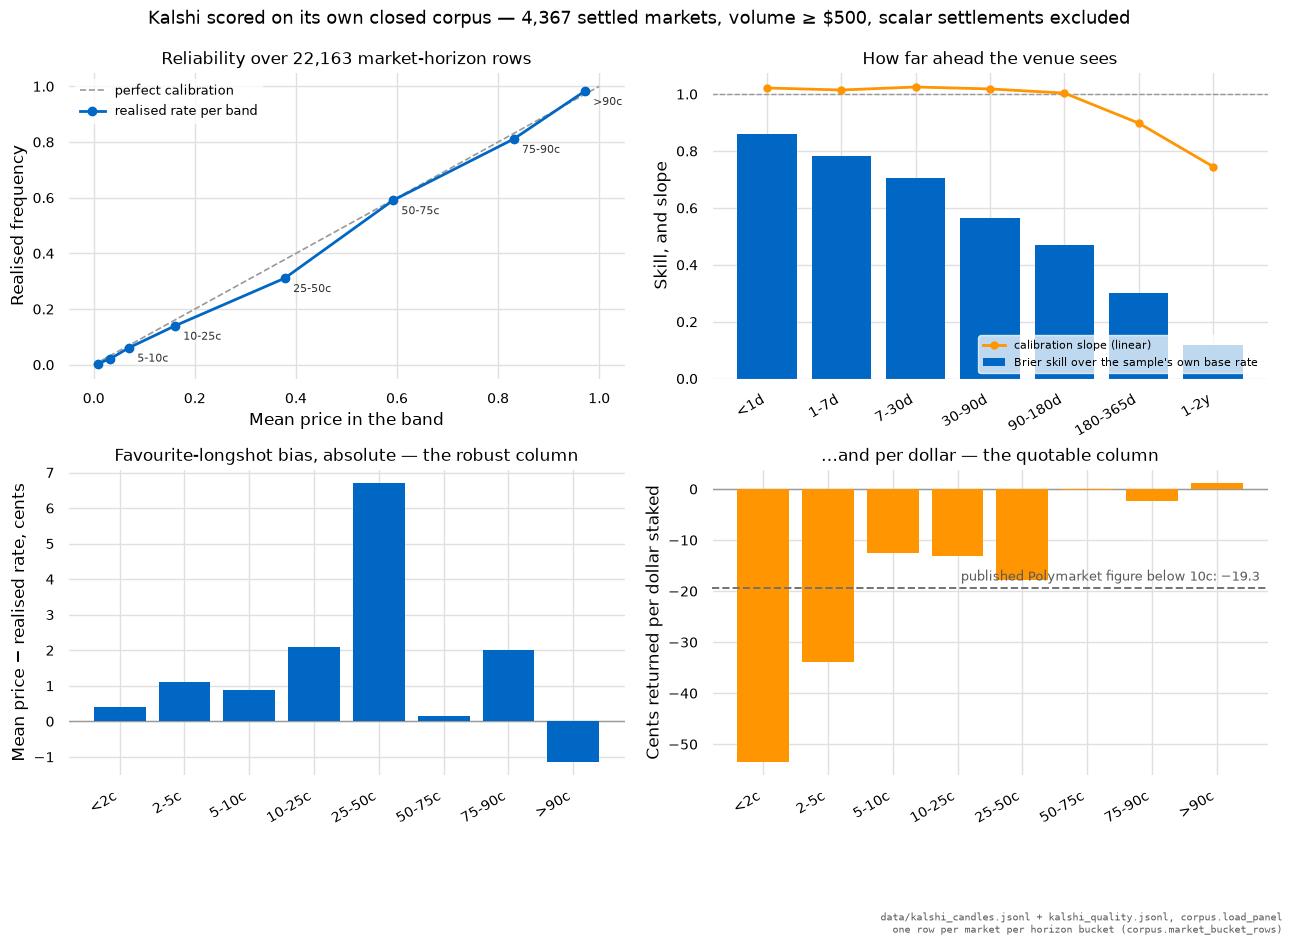

In [39]:
figure, ((tl, tr), (bl, br)) = pyplot.subplots(2, 2, figsize=(13, 9.5))

bands = [r for r in longshot if r["n"]]
tl.plot([0, 1], [0, 1], color="0.6", lw=1.2, ls="--", label="perfect calibration")
tl.plot([r["mean_price"] for r in bands], [r["realised"] for r in bands],
        color=BLUE, lw=2.0, marker="o", markersize=6, label="realised rate per band")
for row in bands:
    # The two lowest bands sit on top of each other at the origin; labelling them
    # produces overlapping text that says less than the band edges already do.
    if row["band"] in ("<2c", "2-5c"):
        continue
    tl.annotate(row["band"], (row["mean_price"], row["realised"]),
                textcoords="offset points", xytext=(6, -10), fontsize=8, alpha=0.8)
tl.set_xlabel("Mean price in the band")
tl.set_ylabel("Realised frequency")
tl.set_title(f"Reliability over {len(price):,} market-horizon rows", fontsize=12)
tl.legend(loc="upper left", fontsize=9)

labels = [s["label"] for s in horizon_stats]
positions = range(len(labels))
tr.bar(positions, [s["skill"] for s in horizon_stats], color=BLUE, zorder=2,
       label="Brier skill over the sample's own base rate")
tr.plot(positions, [s["slope_linear"] for s in horizon_stats], color=ORANGE, lw=2.0,
        marker="o", markersize=5, zorder=3, label="calibration slope (linear)")
tr.axhline(1.0, color="0.6", lw=1.0, ls="--")
tr.set_xticks(list(positions), labels, rotation=30, ha="right")
tr.set_ylabel("Skill, and slope")
tr.set_title("How far ahead the venue sees", fontsize=12)
tr.legend(loc="lower right", fontsize=8)

bl.axhline(0.0, color="0.6", lw=1.0)
bl.bar(range(len(bands)), [r["gap_cents"] for r in bands], color=BLUE, zorder=2)
bl.set_xticks(range(len(bands)), [r["band"] for r in bands], rotation=30, ha="right")
bl.set_ylabel("Mean price − realised rate, cents")
bl.set_title("Favourite-longshot bias, absolute — the robust column", fontsize=12)

br.axhline(0.0, color="0.6", lw=1.0)
br.bar(range(len(bands)), [r["per_dollar"] for r in bands], color=ORANGE, zorder=2)
br.set_xticks(range(len(bands)), [r["band"] for r in bands], rotation=30, ha="right")
br.set_ylabel("Cents returned per dollar staked")
br.set_title("…and per dollar — the quotable column", fontsize=12)
br.axhline(-19.3, color="0.45", lw=1.4, ls="--", zorder=3)
br.annotate("published Polymarket figure below 10c: −19.3", (1.0, -19.3),
            xycoords=("axes fraction", "data"), textcoords="offset points",
            xytext=(-6, 5), ha="right", fontsize=9, color="0.35")

figure.suptitle("Kalshi scored on its own closed corpus — 4,367 settled markets, "
                "volume ≥ $500, scalar settlements excluded", fontsize=13)
figure.tight_layout()
stamp("data/kalshi_candles.jsonl + kalshi_quality.jsonl, corpus.load_panel",
      "one row per market per horizon bucket (corpus.market_bucket_rows)",
      figure=figure)

## 10. Discovery — finding the markets worth watching

Three routes exist and only one of them is the spine.

**`/markets` is not it.** A 20,000-row walk of `status=open` returns *zero* rows
in Economics, Financials, Politics or Elections, because auto-generated
multivariate sports parlays — `KXMVECROSSCATEGORY` and friends — fill the first
twenty pages. The route is not broken; it is ordered against you.

*(The three measurements in this section — the swamped `/markets` walk, the
89-request event walk, and the empty nested lists on settled pages — were made
by the harvest that built `data/` and are recorded in `utils/kalshi.py`. They
are quoted here rather than re-run, because each one costs tens of requests to
reproduce and none of them changes the conclusion.)*

**`/events` is the discovery spine.** It excludes multivariate events, and each
event carries `category`, `series_ticker`, `settlement_sources` and
`mutually_exclusive` — everything needed to classify a ladder. With
`with_nested_markets=true` one walk returns the whole open universe with quotes
attached: 14,444 open events in 89 requests, 5,296 of them in the four target
categories. **But never pass `with_nested_markets` with `status="settled"`**: on
a settled page, 61 of 100 events came back with an empty `markets` list, every
one a pre-cutoff event whose markets live in the historical tier, and an empty
list is indistinguishable from an event that never had markets.

**`/series` is the spine for *this* project**, and that is the part worth
arguing. The whole 14,392-series catalogue arrives in one call, carrying the
settlement sources — so the filter that matters here is not liquidity or volume
or category, it is **"does this contract settle on a statistic we already
ingest"**. That question is answered offline, once, for the entire venue, and it
reduces 14,392 series to a few hundred candidates before a single market is
fetched.

In [40]:
def discover(rows: Sequence[dict[str, Any]], upstream: str,
             categories: Sequence[str] = TARGET,
             frequencies: Sequence[str] = ("monthly", "weekly", "quarterly", "daily"),
             ) -> list[dict[str, Any]]:
    """Series that settle against a house upstream, recur, and sit in a wanted category.

    The three filters do different jobs and only the first is about quality.
    `house_upstream` is the join; `frequency` selects the recurring contracts,
    because a series that reissues monthly gives a *panel* rather than a single
    observation and is the only kind worth a standing watch; `category` drops the
    sports and entertainment tail.
    """
    out = [s for s in rows
           if upstream in (s.get("house_upstream") or [])
           and s["category"] in categories
           and (s.get("frequency") or "").lower() in frequencies]
    return sorted(out, key=lambda s: (s["category"], s["ticker"]))


for upstream in ("BLS", "FRED", "EIA"):
    found = discover(series_rows, upstream)
    print(f"{upstream:5} {len(found):4} recurring series in the target categories, "
          f"of {sum(1 for s in series_rows if upstream in (s.get('house_upstream') or [])):4} "
          f"that settle against it at all")

watchlist = discover(series_rows, "BLS")
print(f"\nthe BLS candidates — a forward distribution over something BLS publishes, "
      f"one per line, first 26 of {len(watchlist)}:")
print(f"  {'series':24} {'frequency':10} {'category':12} title")
for s in watchlist[:26]:
    print(f"  {s['ticker']:24} {s['frequency']:10} {s['category']:12} {s['title'][:44]}")
print(f"  … and {len(watchlist) - 26} more")
print("\nAnd there is the reason this is a CANDIDATE list rather than a watchlist. "
      "'Price of a Burger King 8-piece nuggets' and 'Hass avocado prices this "
      "week' are in it, because `classify_settlement` keyword-matches the "
      "settlement name and URL and those series do cite BLS average-price data "
      "among their sources. The filter is doing what it says; what it says is not "
      "'this settles on a series meida ingests'. Getting from here to a watchlist "
      "needs a hand-maintained map from house series to Kalshi series — the same "
      "thing `mcp_server/cdc_datasets.py` already is for Socrata, and the same "
      "conclusion the research doc reached about Polymarket's 4,000 dirty tag "
      "slugs. The automated step narrows 14,392 series to "
      f"{len(watchlist)}; a person has to do the last mile, once.")

BLS     84 recurring series in the target categories, of  259 that settle against it at all
FRED    65 recurring series in the target categories, of  390 that settle against it at all
EIA     16 recurring series in the target categories, of   64 that settle against it at all

the BLS candidates — a forward distribution over something BLS publishes, one per line, first 26 of 84:
  series                   frequency  category     title
  CPI                      monthly    Economics    CPI
  CPIAPPAREL               monthly    Economics    CPI on apparel
  CPICORE                  monthly    Economics    CPI core
  CPICOREYOY               monthly    Economics    Core inflation
  CPIFOOD                  monthly    Economics    CPI on food
  CPIGAS                   monthly    Economics    CPI on gas
  CPISHELTER               monthly    Economics    CPI on shelter
  CPIUSEDCAR               monthly    Economics    CPI on used cars
  CPIYOY                   monthly    Economics    Infla

In [41]:
# And the drill-down, live: one call resolves a series into its open events, which
# is where a watchlist refresh would start each day.
LIVE.spend("GET /events?series_ticker=&status=open", "KXCPIYOY — the open events")
open_events = list(LIVE.reader.events(cap=50, series_ticker="KXCPIYOY", status="open"))
print(f"KXCPIYOY has {len(open_events)} open events right now:")
for event in open_events:
    print(f"  {event['event_ticker']:22} mutually_exclusive "
          f"{str(event.get('mutually_exclusive')):5}  {event['title']}")
print("\nNote what is missing: the October event. Kalshi lists the next print and "
      "then some later ones, not a contiguous run, so a monitor that assumes a "
      "rung per month will report a hole that is a listing decision rather than a "
      "gap in the data. Confirm the event set from the route; do not generate it "
      "from a calendar.")
print(f"\nDaily cost of a standing watch on this shape, counted rather than "
      f"estimated: one /series call for the catalogue (needed rarely), one /events "
      f"call per watched series, and one /events?with_nested_markets call per open "
      f"event to refresh every rung's quote at once. For the "
      f"{len(watchlist)} BLS series above that is under a hundred requests a day, "
      f"which is cheaper than the existing BLS pull and needs no key.")

KXCPIYOY has 3 open events right now:
  KXCPIYOY-26SEP         mutually_exclusive False  Inflation in September 2026 (CPI YoY)
  KXCPIYOY-26NOV         mutually_exclusive False  Inflation in November 2026 (CPI YoY)
  KXCPIYOY-26DEC         mutually_exclusive False  Inflation in December 2026 (CPI YoY)

Note what is missing: the October event. Kalshi lists the next print and then some later ones, not a contiguous run, so a monitor that assumes a rung per month will report a hole that is a listing decision rather than a gap in the data. Confirm the event set from the route; do not generate it from a calendar.

Daily cost of a standing watch on this shape, counted rather than estimated: one /series call for the catalogue (needed rarely), one /events call per watched series, and one /events?with_nested_markets call per open event to refresh every rung's quote at once. For the 84 BLS series above that is under a hundred requests a day, which is cheaper than the existing BLS pull and needs n

## 11. What Kalshi is good for, and the limits on saying so

**What it is good for, concretely.**

*A forward distribution over a statistic the house already stores.* This is the
thing nothing else in the stack does. `KXCPIYOY-26SEP` is a 21-rung density over
a number that will be published on 14 October and joined to `CUUR0000SA0` the
same morning; section 2 verified that join on 46 settled ladders and section 4.1
verified that the density was informative and imprecise in the way a forecast
should be. The same construction exists for core CPI, the unemployment rate,
payrolls, core PCE, the fed funds target and forty-odd series that name their
FRED id outright.

*A settled corpus with the answer attached.* 100,233 settled markets, 4,393
stored daily paths back to September 2021, and `expiration_value` carrying what
the world actually did rather than merely which side won. That is a
calibration dataset with ground truth, and section 9 measured it: Brier skill
0.63 overall, 0.86 a day out, and about 0.1 at one to two years.

*Resolution that can be checked afterwards.* No oracle, no bond, no vote, and
— for the statistical series — no judgement. The three eight-figure Polymarket
resolution controversies in the research doc have no analogue that could occur
here, because there is nothing to adjudicate.

**What it is not good for.**

*Conflict, permanently.* Section 8 established the absence by searching 105,205
contract texts, and 17 CFR 40.11(a)(1) says it will stay absent. The consequence
of a war is listable; the war is not.

*The multi-year horizon, in practice.* Kalshi formally lists inflation to
December 2036, which beats every Polymarket horizon. Section 4.4 read one of
those ladders: thirteen rungs, five monotonicity violations on mids, spreads
from 21 to 97 cents, and 1,660 contracts of lifetime volume across all of
them. The
horizon exists and the price does not, and the collateral discount at ten years
is worth more than most of those quotes are wide.

*Anything about who is on the other side.* No holder data, no wallet
concentration, no dispute record. `metrics.VENUE_COVERAGE` marks all three "no"
for this venue.

**The limit on redistribution, which is a constraint on this repository and not
a footnote.** Kalshi's market data needs no key and no account, and its
Developer Agreement is the reason that is not the end of the matter: the terms
permit building tools on the API and **prohibit redistributing raw market data
to third parties**. *(As recorded in the research doc's venue table; the
agreement itself was not fetched by this notebook, and anyone acting on it
should read it rather than this sentence.)*

Three consequences, all of which this directory already satisfies:

1. The harvested corpus under `data/` is **gitignored and regenerable**, per the
   repo's own convention for exported catalogues. It is a local analysis
   artefact, not a published dataset, and nothing commits it.
2. What leaves this notebook is **derived**: densities, coherence counts,
   calibration statistics, agreement rates. The printed tables quote individual
   quotes only where a specific quote *is* the finding — the zero `liquidity`
   field, the 2036 ladder's violations — which is comment on the data rather
   than a copy of the feed.
3. If the read path ever becomes a `clients/kalshi.py` with MCP tools, the
   redistribution question moves from "may we store this" to "may a model
   hand it onward", and that needs the agreement read properly before the
   first tool is written. Polymarket has no equivalent clause; Kalshi does, and
   it is the price of the better provenance.

**And the one open question this notebook could not close.** The September
ladder says the implied median is a print near 3.6 against August's 3.4. Whether
that is information or the front rung being interpolated is not answerable from
public data — `metrics.NOT_COMPUTABLE["market_maker_identity"]` says why, and the
$217 of bid depth behind the best rung on the venue's flagship macro ladder is
the reason it matters. The contract settles on arithmetic. The price is still
only as good as the two hundred dollars standing behind it.

In [42]:
LIVE.account()
print()
print(f"house upstreams called: 1 BLS POST, 1 FRED GET")
print(f"everything else came off {DATA}, which is gitignored and regenerable")
print(f"no credential was constructed or sent to Kalshi: the only header was "
      f"{kalshi.USER_AGENT!r}")

16 outbound calls of 20 budgeted, of which 14 went to Kalshi (0 retried on 429)
   1. GET /historical/cutoff             the moving tier boundary
   2. GET markets…                       live market lookup
   3. GET historical…                    historical market lookup
   4. GET series…                        live candlestick path
   5. GET historical…                    historical candlestick path
   6. GET /series/KXCPIYOY               settlement sources, terms, fee family
   7. POST bls /timeseries/data          CUUR0000SA0 with 12-month calculations
   8. GET fred /series/observations      CPIAUCNS and CPIAUCSL levels
   9. GET /events/KXCPIYOY-26SEP         with_nested_markets — 21 live rungs
  10. GET /markets/…/orderbook           KXCPIYOY-26SEP-T3.6
  11. GET /markets/…/orderbook           KXCPIYOY-26SEP-T3.5
  12. GET /markets/…/orderbook           KXCPIYOY-26SEP-T4.5
  13. GET /events/KXUSCPIYEAR-37FEB01    with_nested_markets — the 2036 ladder
  14. GET /historical/market